# Batch Quality and Equipment Reliability: complete analysis

This single notebook runs the whole analysis in order: data audit and cleaning, exploratory
analysis, the batch classifier, equipment reliability, process control and trend, the risk view
and back-test, and the optional demand forecast. Each section is explained in its own text cell.
It reproduces the results in reports/tables and reports/figures.

# 01 Data audit and cleaning

**Purpose.** This notebook checks the four raw files, cleans and links them, and
verifies every headline claim in the proposal (version 3.0) against the data.
Nothing in the proposal is taken on trust: each claim is either confirmed, or
flagged with the value the data actually shows.

**Sources.** Batch production records (60,000 rows), equipment maintenance records
(60,000 rows, one per batch), sales transactions (150,000 rows) and inventory
movements (162,000 rows).

**Output.** Processed Parquet tables in `data/processed/`, and the quality-check
register in `reports/tables/data_quality_register.csv`.

In [1]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


## 1. Load the raw files

The raw files are read exactly as supplied. They are never edited in place, so the
analysis can always be traced back to the original extract.

In [2]:
from src.config import RAW_FILES, DATA_RAW
from src.data_io import load_raw

print("Raw files present:", {k: (DATA_RAW / v).exists() for k, v in RAW_FILES.items()})
raw = {key: load_raw(key) for key in RAW_FILES}
summary = pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1]} for k, v in raw.items()}).T
display(summary)
display(raw["batch"].head(3))

Raw files present: {'batch': True, 'maintenance': True, 'sales': True, 'inventory': True}


,rows,columns
batch,60000,30
maintenance,60000,16
sales,150000,23
inventory,162000,10


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,maintenance_days_ago,upstream_equipment_id,downstream_equipment_id,ahu_id,operator_id,operator_experience_years,temp_avg,temp_variance,pressure_avg,pressure_variance,humidity_avg,production_hours,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,78,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0388,3,23.71,0.149,1.001,0.0233,44.0,26.7,99.6,95.0,99.79,100.69,0.098,17.26,1,NaN
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,79,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0319,8,22.11,0.335,1.006,0.0729,47.1,21.4,99.8,95.0,99.21,99.55,0.104,16.67,1,NaN
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,79,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0413,2,22.59,0.124,NaN,0.0728,48.7,19.6,99.6,95.0,98.62,100.18,0.066,15.06,1,NaN


## 2. Missing values in the batch file

Missing values are reported before any cleaning. Process readings are missing in
roughly one to two percent of rows, and dissolution time is missing for about a
quarter of batches. Dissolution is a release test, so it is not a predictor; the
missingness is kept as a flag rather than imputed.

Columns with missing values: 11 of 30


,missing_percent
rejection_reason,96.88
dissolution_time_min,25.10
humidity_avg,1.44
temp_variance,1.32
pressure_variance,1.19
raw_material_quality,1.14
pressure_avg,0.98
temp_avg,0.74
impurity_level,0.50
production_hours,0.48


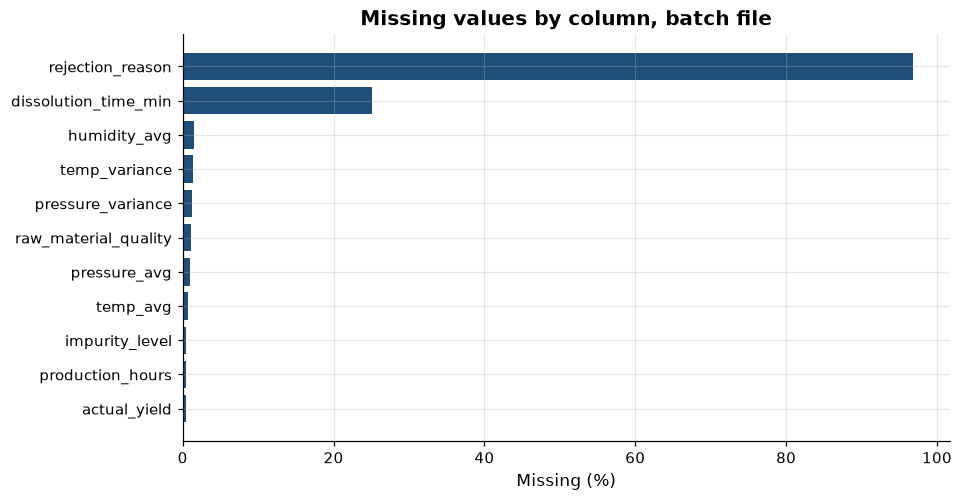

In [3]:
# Share of missing values for each column in the batch file, highest first.
missing = raw["batch"].isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"Columns with missing values: {len(missing)} of {raw['batch'].shape[1]}")
display(missing.mul(100).round(2).rename("missing_percent").to_frame())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(missing.index[::-1], missing.values[::-1] * 100, color=PRIMARY)
ax.set_xlabel("Missing (%)")
ax.set_title("Missing values by column, batch file")
save_figure(fig, "01_missingness_batch")
plt.show()

## 3. Run the cleaning pipeline and the quality register

The cleaning step links the batch and maintenance files one-to-one, checks each
shared field, harmonises the rejection labels, pseudonymises operator identifiers,
and records every check in a register. Each check is marked PASS, FLAG or INFO.
A FLAG is a finding that needs attention, not a hidden error.

In [4]:
from src.cleaning import run_cleaning

# Run the full cleaning step. Processed tables are written to data/processed/.
tables = run_cleaning(save=True)
register = tables["quality_register"]
print(f"Quality checks run: {len(register)}")
print(register["status"].value_counts().to_string())
display(register)

Quality checks run: 45
status
PASS    33
INFO    10
FLAG     2


,area,check,observed,expected,status,note
0,Batch file,Row count,60000,"60,000",PASS,
1,Batch file,Batch IDs unique,60000,equal to row count,PASS,
2,Maintenance file,Row count,60000,"60,000",PASS,
3,Linkage,Batch IDs match maintenance IDs,100.00%,100%,PASS,
4,Linkage,Agreement: equipment_id,100.00%,100%,PASS,
5,Linkage,Agreement: equipment_age_days,100.00%,100%,PASS,
6,Linkage,Agreement: maintenance_days_ago,100.00%,100%,PASS,
7,Linkage,Agreement: batch_size,100.00%,100%,PASS,
8,Linkage,Agreement: operator_experience_years,100.00%,100%,PASS,
9,Linkage,Agreement: batch_passed,100.00%,100%,PASS,


## 4. Verify the proposal's claims

The table below sets each proposal claim against the value observed in the data.
One claim does not match the data: the rejection-reason agreement between files.
The data gaps the proposal describes (no opening stock, no repair times) are confirmed.

In [5]:
batches = tables["batches"]
sales_clean = tables["sales"]


def observed(check_text: str) -> str:
    """Return the observed value of the quality register row whose check text matches."""
    row = register[register["check"].str.contains(check_text, regex=False)].iloc[0]
    return str(row["observed"])


failed = batches[batches[TARGET_COL] == 1]
claims = pd.DataFrame(
    [
        ("Overall failure rate 3.1% (1,875 failed batches)",
         f"{batches[TARGET_COL].mean():.2%} ({int(batches[TARGET_COL].sum()):,})", "Confirmed"),
        ("Critical maintenance batches fail at 6.9%",
         f"{batches.loc[batches.maintenance_status == 'Critical', TARGET_COL].mean():.2%}", "Confirmed"),
        ("Critical maintenance applies to 476 batches",
         f"{(batches.maintenance_status == 'Critical').sum():,}", "Confirmed"),
        ("Dissolution time missing for about 25% of batches",
         f"{batches.dissolution_time_min.isna().mean():.2%}", "Confirmed"),
        ("Assay failures are 29% of all failures",
         f"{(failed.failure_mode == 'Assay').mean():.1%}", "Confirmed"),
        ("Dissolution failures are 18% of all failures",
         f"{(failed.failure_mode == 'Dissolution').mean():.1%}", "Confirmed"),
        ("Batch and maintenance IDs match 100%", observed("Batch IDs match maintenance IDs"), "Confirmed"),
        ("Batch date equals maintenance date on every batch",
         observed("Batch date equals maintenance date"), "Confirmed"),
        ("Equipment, section and pass/fail agree across the two batch files",
         observed("Agreement: equipment_id") + " (equipment)", "Confirmed"),
        ("Rejection reason agrees on only about 3% of rows",
         observed("Rejection reason agreement"), "NOT CONFIRMED: files agree on every row"),
        ("Sales and inventory join on Reference ID for all 150,000 sales",
         observed("Sale_Out movements linked"), "Confirmed"),
        ("300 products, 4 branches, 30 suppliers in sales",
         "300 / 4 / 30", "Confirmed"),
        ("Inventory data has no opening stock (stock on hand cannot be verified)",
         observed("Opening stock available"), "Confirmed as a gap"),
    ],
    columns=["Proposal claim", "Observed in the data", "Status"],
)
display(claims.set_index("Proposal claim"))

,Observed in the data,Status
Proposal claim,,
"Overall failure rate 3.1% (1,875 failed batches)","3.12% (1,875)",Confirmed
Critical maintenance batches fail at 6.9%,6.93%,Confirmed
Critical maintenance applies to 476 batches,476,Confirmed
Dissolution time missing for about 25% of batches,25.09%,Confirmed
Assay failures are 29% of all failures,29.1%,Confirmed
Dissolution failures are 18% of all failures,18.2%,Confirmed
Batch and maintenance IDs match 100%,100.00%,Confirmed
Batch date equals maintenance date on every batch,100.00%,Confirmed
"Equipment, section and pass/fail agree across the two batch files",100.00% (equipment),Confirmed


## 5. Harmonising the failure modes

The raw rejection file uses fourteen labels, several of which describe the same
failure in different words (for example, "Visible particulate matter" and "Foreign
matter / visible particles"). The labels are grouped into ten failure modes so that
the Pareto analysis is readable. Every failed batch is kept; none is dropped.

,raw_label,failure_mode
0,Assay out of specification,Assay
1,Blend uniformity failure,Blend uniformity
2,Phase separation / homogeneity failure,Blend uniformity
3,Dissolution failure,Dissolution
4,Microbial limit failure,Microbial
5,Bacterial endotoxin above limit,Microbial
6,Sterility test failure,Microbial
7,Foreign matter / visible particles,Particulates
8,Visible particulate matter,Particulates
9,Hardness / friability out of specification,Physical strength


Failed batches with a harmonised mode: 1,875 of 1,875


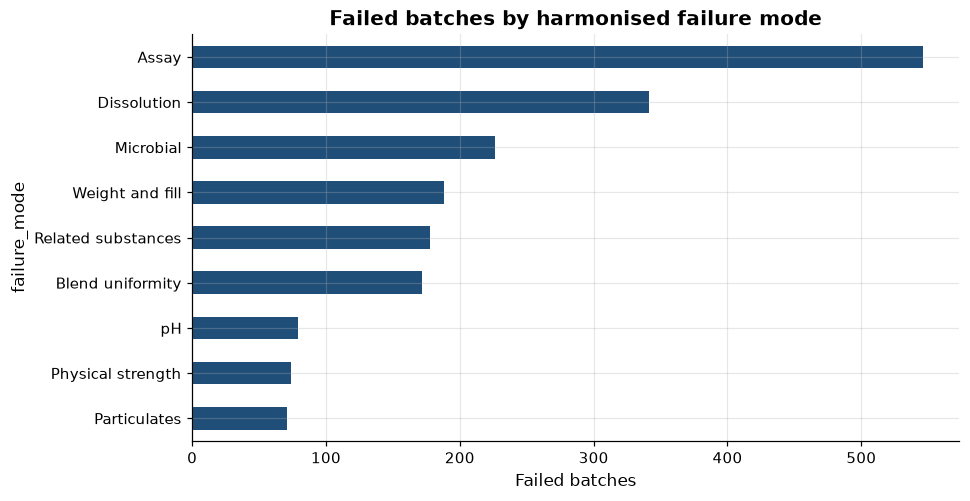

In [6]:
from src.cleaning import FAILURE_MODE_MAP

# The mapping used for harmonisation, grouped by failure mode.
mapping = pd.DataFrame(sorted(FAILURE_MODE_MAP.items(), key=lambda kv: kv[1]),
                       columns=["raw_label", "failure_mode"])
display(mapping)

modes = failed["failure_mode"].value_counts()
print(f"Failed batches with a harmonised mode: {modes.sum():,} of {len(failed):,}")
fig, ax = plt.subplots(figsize=(9, 4.8))
modes.sort_values().plot.barh(ax=ax, color=PRIMARY)
ax.set_xlabel("Failed batches")
ax.set_title("Failed batches by harmonised failure mode")
save_figure(fig, "02_failure_modes")
plt.show()

## 6. Sales and inventory reconciliation

Sales and inventory are analysed separately from production, because the proposal
states that the two groups share no key. Sales have no cancelled-order stock
adjustment: the inventory file still records stock leaving for cancelled orders,
which is flagged in the register. Cancelled orders are excluded from demand.

In [7]:
# Reconcile the inventory Sale_Out movements against the sales file.
inventory = tables["inventory"]
out = inventory[inventory["Movement_Type"] == "Sale_Out"]
recon = pd.DataFrame(
    {
        "Sale_Out movements": [len(out)],
        "Linked to a sale": [out["Reference_ID"].isin(sales_clean["Sale_ID"]).sum()],
        "Quantity matches sale": [
            (out.set_index("Reference_ID")["Quantity_Change"].abs()
             == sales_clean.set_index("Sale_ID")["Quantity"].reindex(out["Reference_ID"]).values).sum()
        ],
        "Recorded against cancelled orders": [
            sales_clean.set_index("Sale_ID").loc[out["Reference_ID"], "is_cancelled"].sum()
        ],
    }
)
display(recon.T.rename(columns={0: "count"}))

,count
Sale_Out movements,150000
Linked to a sale,150000
Quantity matches sale,150000
Recorded against cancelled orders,6045


## 7. What this notebook established

* The batch and maintenance files are a clean, one-to-one pair. The linkage is complete.
* One proposal statement is not supported by the data: the rejection-reason agreement
  between the two batch files. The files agree on every row. The proposal's date
  conversion is consistent with the ISO dates supplied.
* Inventory has no opening balance, so stock on hand cannot be computed. Stock-out and
  expiry modules remain out of scope, as the proposal states.
* Operator identifiers are pseudonymised before any output is written.

# 02 Exploratory analysis and research questions

**Purpose.** Answer the research questions in proposal section 4 with evidence:
which batches fail, what drives failure, how the failure modes are distributed, and
how the failure rate has changed over time. The sales and inventory data are summarised
at the end, as context for the optional demand module.

All rates are shown with 95 percent Wilson confidence intervals, because the
Critical maintenance group is small and point estimates alone would overstate precision.

In [8]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [9]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Headline figures

In [10]:
from src.reliability import rate_table, add_bands

headline = pd.Series(
    {
        "Batches": f"{len(batches):,}",
        "Failed batches": f"{int(batches[TARGET_COL].sum()):,}",
        "Failure rate": f"{batches[TARGET_COL].mean():.2%}",
        "Equipment units": batches["equipment_id"].nunique(),
        "Drugs": batches["drug_name"].nunique(),
        "Production years": f"{batches['year'].min()} to {batches['year'].max()}",
    },
    name="value",
)
display(headline.to_frame())

,value
Batches,"60,000"
Failed batches,"1,875"
Failure rate,3.12%
Equipment units,13
Drugs,40
Production years,2007 to 2026


## 2. What drives failure: the main factors

Each panel shows the failure rate for one factor, with its 95 percent interval.
These are unadjusted rates. The proposal correctly warns that maintenance status,
equipment age, operator experience and dosage form are correlated, so these
differences are tested after adjustment in notebooks 03 and 04.

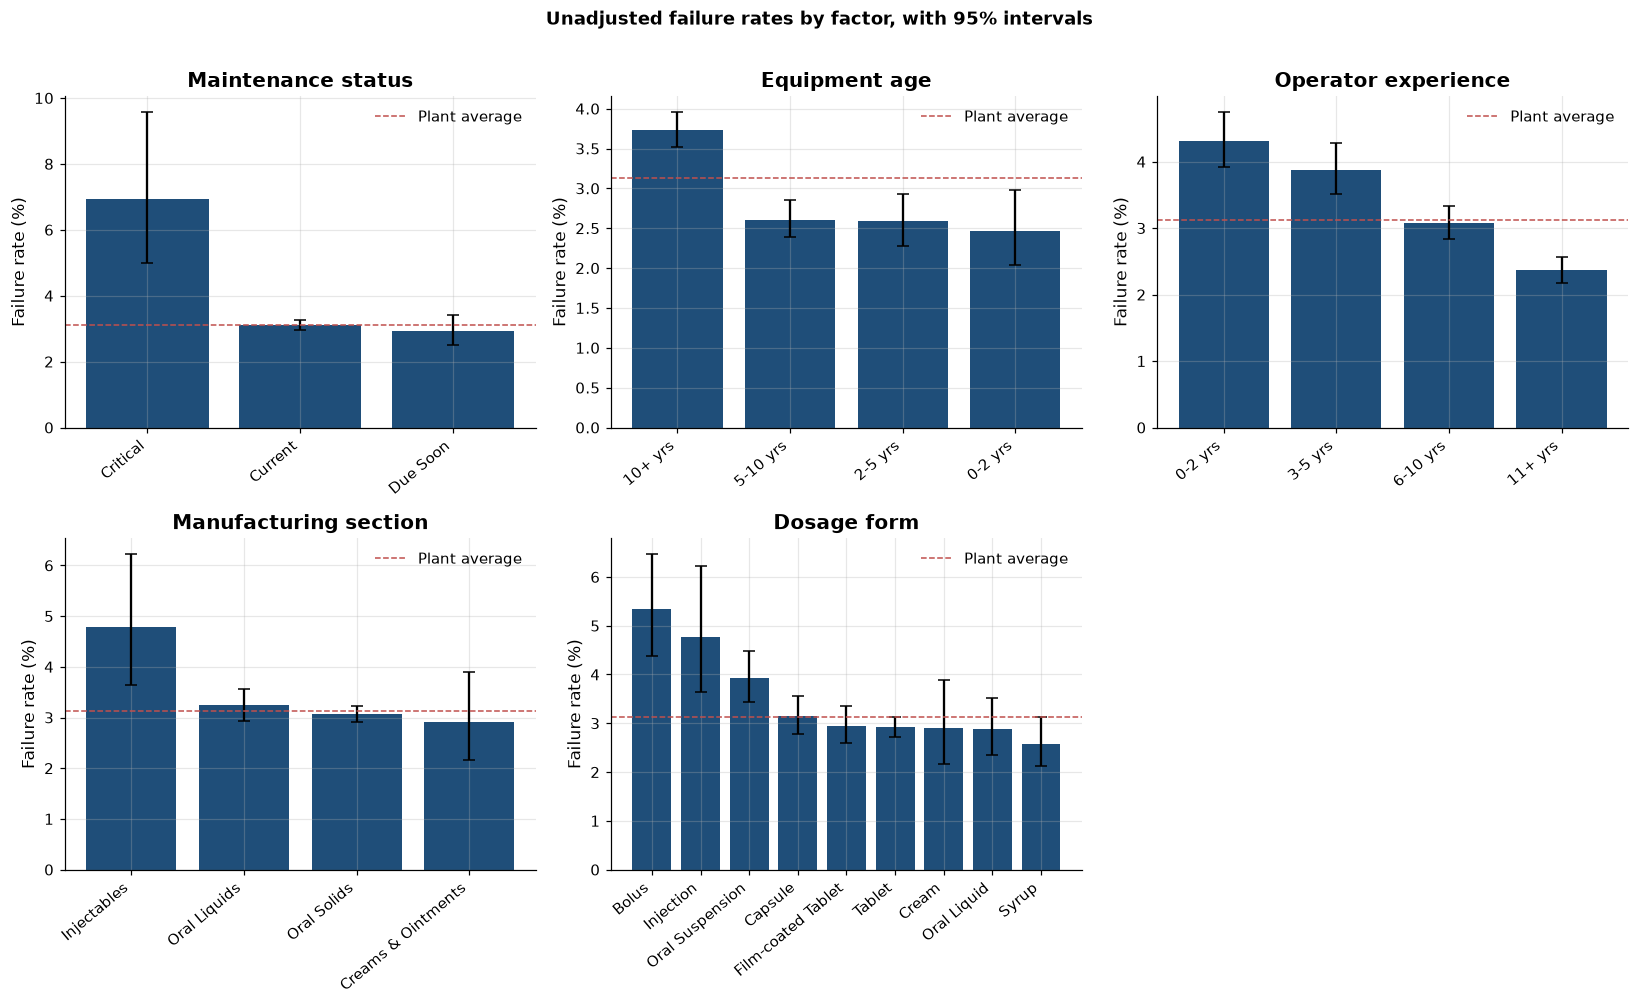

,batches,failures,failure_rate,ci_low,ci_high
maintenance_status,,,,,
Critical,476,33,0.0693,0.0498,0.0958
Current,54240,1687,0.0311,0.0297,0.0326
Due Soon,5284,155,0.0293,0.0251,0.0342


,batches,failures,failure_rate,ci_low,ci_high
age_band,,,,,
0-2 yrs,4185,103,0.0246,0.0203,0.0298
2-5 yrs,9440,244,0.0258,0.0228,0.0292
5-10 yrs,18025,470,0.0261,0.0238,0.0285
10+ yrs,28350,1058,0.0373,0.0352,0.0396


,batches,failures,failure_rate,ci_low,ci_high
operator_band,,,,,
0-2 yrs,9136,394,0.0431,0.0391,0.0475
3-5 yrs,9704,376,0.0387,0.0351,0.0428
6-10 yrs,18473,568,0.0307,0.0284,0.0333
11+ yrs,22687,537,0.0237,0.0218,0.0257


,batches,failures,failure_rate,ci_low,ci_high
manufacturing_section,,,,,
Creams & Ointments,1480,43,0.0291,0.0216,0.0389
Injectables,1068,51,0.0478,0.0365,0.0622
Oral Liquids,12170,394,0.0324,0.0294,0.0357
Oral Solids,45282,1387,0.0306,0.0291,0.0323


,batches,failures,failure_rate,ci_low,ci_high
dosage_form,,,,,
Bolus,1800,96,0.0533,0.0439,0.0647
Capsule,8066,254,0.0315,0.0279,0.0355
Cream,1480,43,0.0291,0.0216,0.0389
Film-coated Tablet,7855,232,0.0295,0.0260,0.0335
Injection,1068,51,0.0478,0.0365,0.0622
Oral Liquid,3127,90,0.0288,0.0235,0.0352
Oral Suspension,5242,206,0.0393,0.0344,0.0449
Syrup,3801,98,0.0258,0.0212,0.0313
Tablet,27561,805,0.0292,0.0273,0.0313


In [11]:
banded = add_bands(batches)
panels = [
    ("maintenance_status", "Maintenance status", ["Current", "Due Soon", "Critical"]),
    ("age_band", "Equipment age", None),
    ("operator_band", "Operator experience", None),
    ("manufacturing_section", "Manufacturing section", None),
    ("dosage_form", "Dosage form", None),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (column, title, order) in zip(axes.flat, panels):
    table = rate_table(banded, [column])
    if order:
        table = table.set_index(column).loc[order].reset_index()
    table = table.sort_values("failure_rate", ascending=False)
    err = np.vstack([table["failure_rate"] - table["ci_low"], table["ci_high"] - table["failure_rate"]])
    ax.bar(table[column].astype(str), table["failure_rate"] * 100, color=PRIMARY,
           yerr=err * 100, capsize=4)
    ax.axhline(batches[TARGET_COL].mean() * 100, color=ALERT, linestyle="--", linewidth=1,
               label="Plant average")
    ax.set_title(title)
    ax.set_ylabel("Failure rate (%)")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")  # right-align rotated labels so long names do not collide
    ax.legend()
axes.flat[-1].axis("off")
fig.suptitle("Unadjusted failure rates by factor, with 95% intervals", fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, "03_failure_drivers")
plt.show()

# Numeric table behind the chart, for the record.
for column in ["maintenance_status", "age_band", "operator_band", "manufacturing_section", "dosage_form"]:
    display(rate_table(banded, [column]).round(4).set_index(column))

## 3. Failure modes: which failures dominate

A Pareto chart shows the failure modes in order of frequency, with the cumulative share.
The proposal's claim that assay and dissolution account for almost half of failures is
tested here. The Pareto view tells the root-cause team where to look first.

,failures,share,cumulative_share
failure_mode,,,
Assay,546,0.2912,0.2912
Dissolution,341,0.1819,0.4731
Microbial,226,0.1205,0.5936
Weight and fill,188,0.1003,0.6939
Related substances,178,0.0949,0.7888
Blend uniformity,172,0.0917,0.8805
pH,79,0.0421,0.9227
Physical strength,74,0.0395,0.9621
Particulates,71,0.0379,1.0000


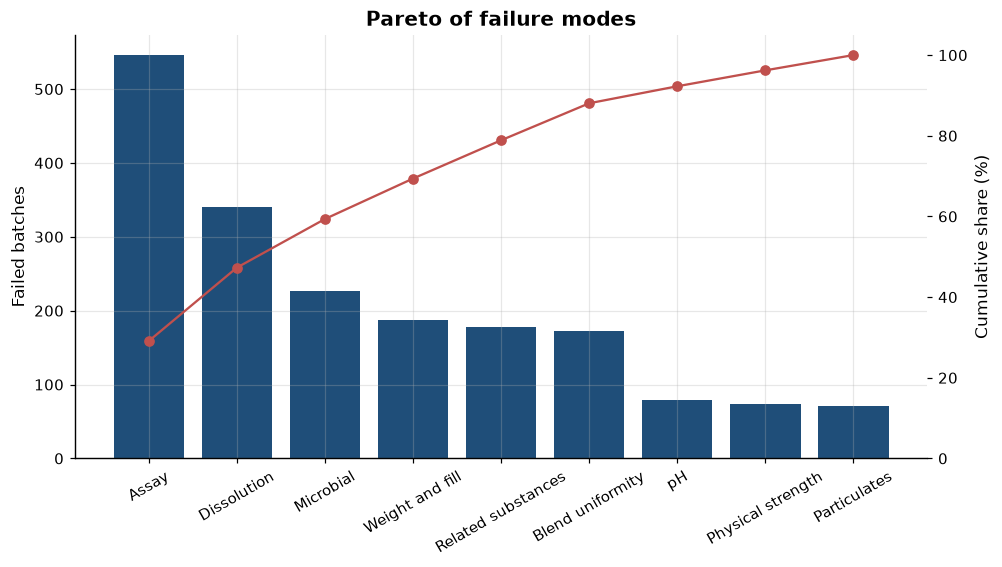

In [12]:
failed = batches[batches[TARGET_COL] == 1]
modes = failed["failure_mode"].value_counts()
pareto = pd.DataFrame({"failures": modes})
pareto["share"] = pareto["failures"] / pareto["failures"].sum()
pareto["cumulative_share"] = pareto["share"].cumsum()
display(pareto.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pareto.index, pareto["failures"], color=PRIMARY)
ax.set_ylabel("Failed batches")
ax.tick_params(axis="x", rotation=30)
ax2 = ax.twinx()
ax2.plot(pareto.index, pareto["cumulative_share"] * 100, color=ALERT, marker="o")
ax2.set_ylabel("Cumulative share (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax.set_title("Pareto of failure modes")
save_figure(fig, "04_failure_pareto")
plt.show()

## 4. Trend over time

The failure rate by production year is shown with its interval. The proposal says the
rate has risen since 2019. The chart shows the full history, from 2007.

,batches,failures,failure_rate,ci_low,ci_high
year,,,,,
2007,2033,59,0.0290,0.0226,0.0373
2008,2048,45,0.0220,0.0165,0.0293
2009,2123,43,0.0203,0.0151,0.0272
2010,2279,43,0.0189,0.0140,0.0253
2011,2357,62,0.0263,0.0206,0.0336
2012,2456,69,0.0281,0.0223,0.0354
2013,2567,77,0.0300,0.0241,0.0373
2014,2539,63,0.0248,0.0194,0.0316
2015,3023,99,0.0327,0.0270,0.0397


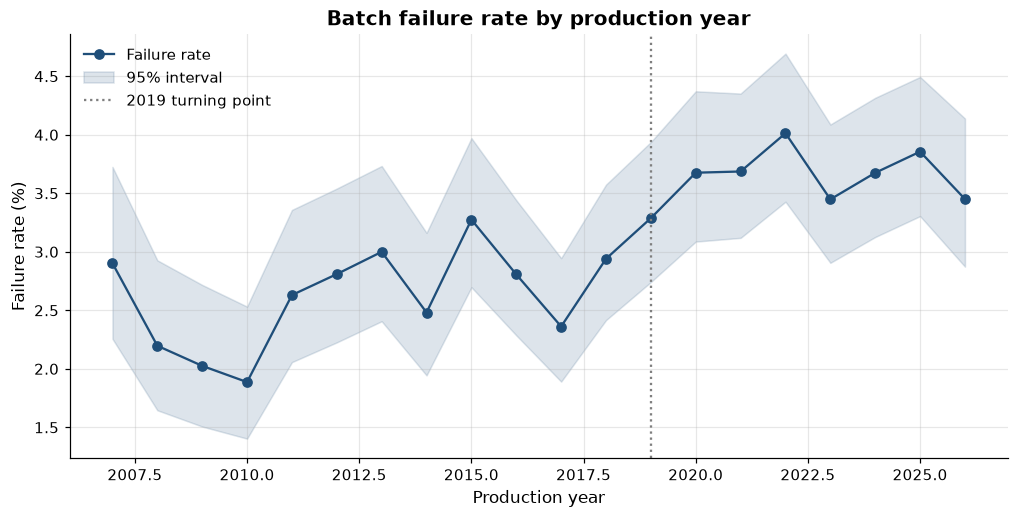

In [13]:
from src.trend import yearly_table

yearly = yearly_table(batches)
display(yearly.round(4).set_index("year"))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly["year"], yearly["failure_rate"] * 100, color=PRIMARY, marker="o", label="Failure rate")
ax.fill_between(yearly["year"], yearly["ci_low"] * 100, yearly["ci_high"] * 100,
                color=PRIMARY, alpha=0.15, label="95% interval")
ax.axvline(2019, color=NEUTRAL, linestyle=":", label="2019 turning point")
ax.set_xlabel("Production year")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Batch failure rate by production year")
ax.legend()
save_figure(fig, "05_yearly_failure_rate")
plt.show()

## 5. Sales and inventory context

The sales file covers 2014 to 2025 and contains no batch-level link to production, so it
is summarised separately. It supports the optional demand module (notebook 07).

,orders,units,net_value_kes_m
Sale_Date,,,
2014,7743,112596,433.1
2015,8096,121468,463.3
2016,9102,133750,594.6
2017,9567,134579,623.7
2018,10299,145026,673.5
2019,11136,155797,787.2
2020,12158,171327,937.6
2021,12929,190461,1048.0
2022,13967,202456,1248.8


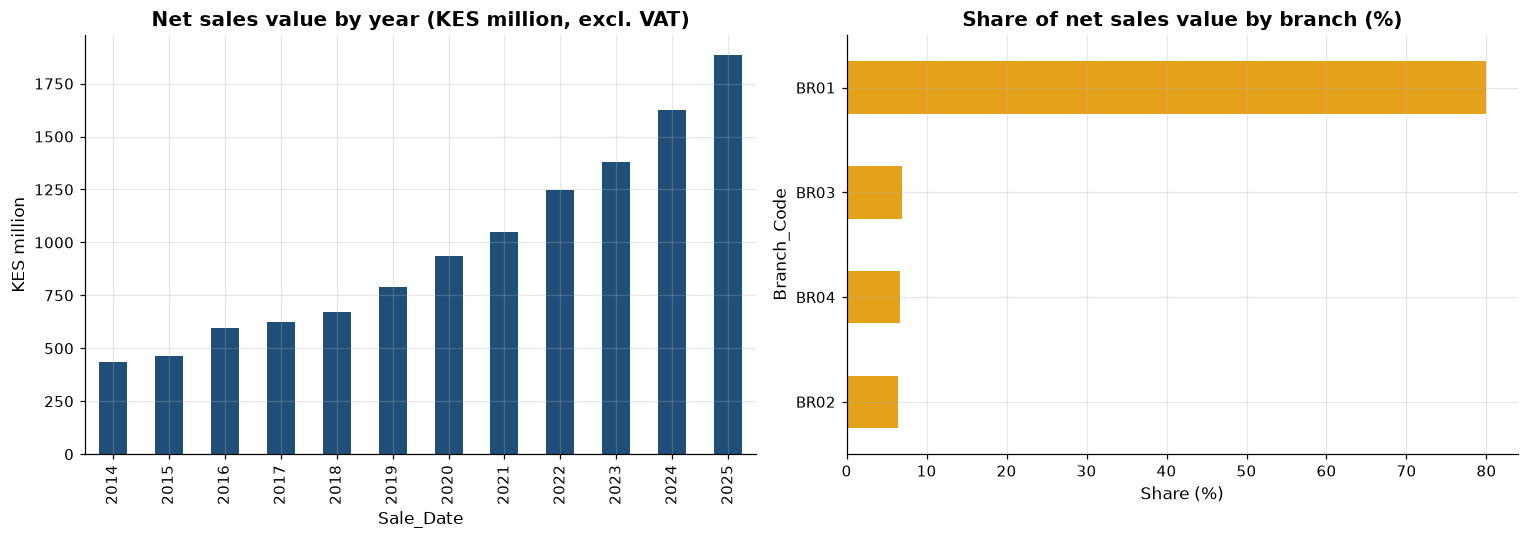

,movements,quantity_change
Movement_Type,,
Goods_Received,12000,4127550
Sale_Out,150000,-2150430


In [14]:
active = sales[sales["is_cancelled"] == 0]
by_year = active.groupby(active["Sale_Date"].dt.year).agg(
    orders=("Sale_ID", "size"),
    units=("Quantity", "sum"),
    net_value_kes_m=("Net_Amount_Excl_VAT_KES", lambda s: s.sum() / 1e6),
)
display(by_year.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_year["net_value_kes_m"].plot.bar(ax=axes[0], color=PRIMARY)
axes[0].set_title("Net sales value by year (KES million, excl. VAT)")
axes[0].set_ylabel("KES million")
share_branch = active.groupby("Branch_Code")["Net_Amount_Excl_VAT_KES"].sum()
(share_branch / share_branch.sum() * 100).sort_values().plot.barh(ax=axes[1], color=ACCENT)
axes[1].set_title("Share of net sales value by branch (%)")
axes[1].set_xlabel("Share (%)")
fig.tight_layout()
save_figure(fig, "06_sales_overview")
plt.show()

movements = inventory.groupby(["Movement_Type"]).agg(movements=("Movement_ID", "size"),
                                                     quantity_change=("Quantity_Change", "sum"))
display(movements)

## 6. Answers to the research questions

The table summarises what the evidence supports. Adjusted answers come from notebooks
03 to 05, and the table will be updated when those are complete.

In [15]:
answers = pd.DataFrame(
    [
        ("Which batches are most likely to fail?",
         "Operator experience, equipment age and raw material quality rank highest, but each is weak alone.",
         "Partly: a weak signal, not a reliable screen (notebook 03)"),
        ("Does maintenance status raise risk after adjustment?",
         "Critical status keeps a clear effect after adjustment; Due Soon does not.",
         "Yes for Critical only (notebook 04)"),
        ("Is the post-2019 rise explained by age, operator or product mix?",
         "Measured factors explain about 60% of the pre-to-post change; the year trend is absorbed after adjustment.",
         "Mostly (notebook 05)"),
        ("Which failure modes dominate?",
         "Assay and dissolution together form roughly 47% of failures.",
         "Yes (this notebook)"),
        ("Do process conditions drift before failures?",
         "Readings stay within limits almost always; prior out-of-control signals only weakly precede failures.",
         "Not materially (notebook 05)"),
        ("Does operator experience matter after controlling for product and equipment?",
         "Yes: the failure rate falls with each experience band.",
         "Yes (notebook 04 and 05)"),
    ],
    columns=["Research question", "Evidence", "Answer"],
)
display(answers.set_index("Research question"))

,Evidence,Answer
Research question,,
Which batches are most likely to fail?,"Operator experience, equipment age and raw material quality rank highest, bu...","Partly: a weak signal, not a reliable screen (notebook 03)"
Does maintenance status raise risk after adjustment?,Critical status keeps a clear effect after adjustment; Due Soon does not.,Yes for Critical only (notebook 04)
"Is the post-2019 rise explained by age, operator or product mix?",Measured factors explain about 60% of the pre-to-post change; the year trend...,Mostly (notebook 05)
Which failure modes dominate?,Assay and dissolution together form roughly 47% of failures.,Yes (this notebook)
Do process conditions drift before failures?,Readings stay within limits almost always; prior out-of-control signals only...,Not materially (notebook 05)
Does operator experience matter after controlling for product and equipment?,Yes: the failure rate falls with each experience band.,Yes (notebook 04 and 05)


# 03 Batch quality classifier (Module A)

**Purpose.** Predict, before release, which batches will fail, and explain the drivers
behind each prediction. This notebook covers the classifier design, the time-separated
validation, model comparison, threshold choice, the test-period result, and the
failure-mode model that proposes a likely cause for each alert.

**Design rules applied.**
1. Only information available before release is used. Assay, dissolution, impurity,
   actual yield and rejection reason are measured at or after release, so they are excluded.
2. Splits follow time: train on 2007 to 2021, validate on 2022 to 2023, test on 2024 to 2026.
3. Imputation medians are fitted on the training period only.
4. The logistic baseline must be beaten by a challenger by a margin before a complex model is adopted.
5. Each model keeps its own decision threshold, chosen on validation, never on test.

In [16]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [17]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Time-separated split and feature set

In [18]:
from src.modeling import split_by_time
from src.features import NUMERIC_FEATURES, feature_columns, FEATURE_LABELS

split = split_by_time(batches)
display(split.describe().round(4).set_index("partition"))

print("Predictors used (pre-release only):")
features_table = pd.DataFrame({"column": feature_columns()})
features_table["label"] = features_table["column"].map(lambda c: FEATURE_LABELS.get(c, c))
display(features_table)

excluded = ["assay_result_purity", "impurity_level", "dissolution_time_min", "actual_yield",
            "rejection_reason", "failure_mode"]
print("Excluded because they are measured at or after release:", ", ".join(excluded))

,period,batches,failed,failure_rate
partition,,,,
Train,2007-2021,41477,1190,0.0287
Validation,2022-2023,7396,276,0.0373
Test,2024-2026,11127,409,0.0368


Predictors used (pre-release only):


,column,label
0,equipment_age_years,Equipment age (years)
1,maintenance_days_ago,Days since maintenance
2,temp_avg,Average temperature
3,temp_variance,Temperature variance
4,pressure_avg,Average pressure
5,pressure_variance,Pressure variance
6,humidity_avg,Average humidity
7,raw_material_quality,Raw material quality
8,operator_experience_years,Operator experience (years)
9,production_hours,Production hours


Excluded because they are measured at or after release: assay_result_purity, impurity_level, dissolution_time_min, actual_yield, rejection_reason, failure_mode


## 2. Fit and compare the models

Three models are trained on the training period: a logistic regression baseline, a random
forest, and gradient boosting (XGBoost). All use class weighting, because only about three
percent of batches fail. The fitting function returns every artefact used below.

In [19]:
from src.modeling import fit_classifier_suite

suite = fit_classifier_suite(batches)
cols = ["roc_auc", "pr_auc", "precision", "recall", "f1", "flag_rate",
        "true_positives", "false_positives", "false_negatives"]

print("VALIDATION (2022-2023): used to compare models and set thresholds")
display(suite["validation_table"][cols].round(4))
print("TEST (2024-2026): reported once, after all choices were made")
display(suite["test_table"][cols].round(4))

thr = {k: round(v, 4) for k, v in suite["thresholds"].items()}
print("Decision thresholds fixed on validation:", thr)
print("Adopted model:", suite["chosen_model"])

VALIDATION (2022-2023): used to compare models and set thresholds


,roc_auc,pr_auc,precision,recall,f1,flag_rate,true_positives,false_positives,false_negatives
model,,,,,,,,,
Logistic regression (baseline),0.5939,0.0533,0.0427,0.8116,0.0811,0.7100,224,5027,52
Random forest,0.5560,0.0449,0.0407,0.8188,0.0776,0.7501,226,5322,50
XGBoost (gradient boosting),0.5169,0.0406,0.0377,0.9638,0.0725,0.9547,266,6795,10


TEST (2024-2026): reported once, after all choices were made


,roc_auc,pr_auc,precision,recall,f1,flag_rate,true_positives,false_positives,false_negatives
model,,,,,,,,,
Logistic regression (baseline),0.5809,0.0563,0.0399,0.8240,0.0761,0.7593,337,8112,72
Random forest,0.5569,0.0439,0.0383,0.8704,0.0733,0.8363,356,8950,53
XGBoost (gradient boosting),0.5409,0.0411,0.0376,0.9804,0.0723,0.9596,401,10277,8


Decision thresholds fixed on validation: {'Logistic regression (baseline)': 0.4938, 'Random forest': 0.2039, 'XGBoost (gradient boosting)': 0.1476}
Adopted model: Logistic regression (baseline)


### Reading the comparison

The question is whether any model separates failing from passing batches well. Threshold
metrics (precision, recall) depend on the threshold chosen, but ROC-AUC and PR-AUC do not.
ROC-AUC of 0.5 means no separation, and the proposal target is 0.80. The boosted models do
not beat the logistic baseline on validation, so the adoption rule keeps the baseline.

## 3. Ranking curves on the test period

The ROC curve shows how well each model ranks failing batches above passing ones. The
precision-recall curve is more informative when failures are rare, as they are here, because
its baseline is the failure rate itself.

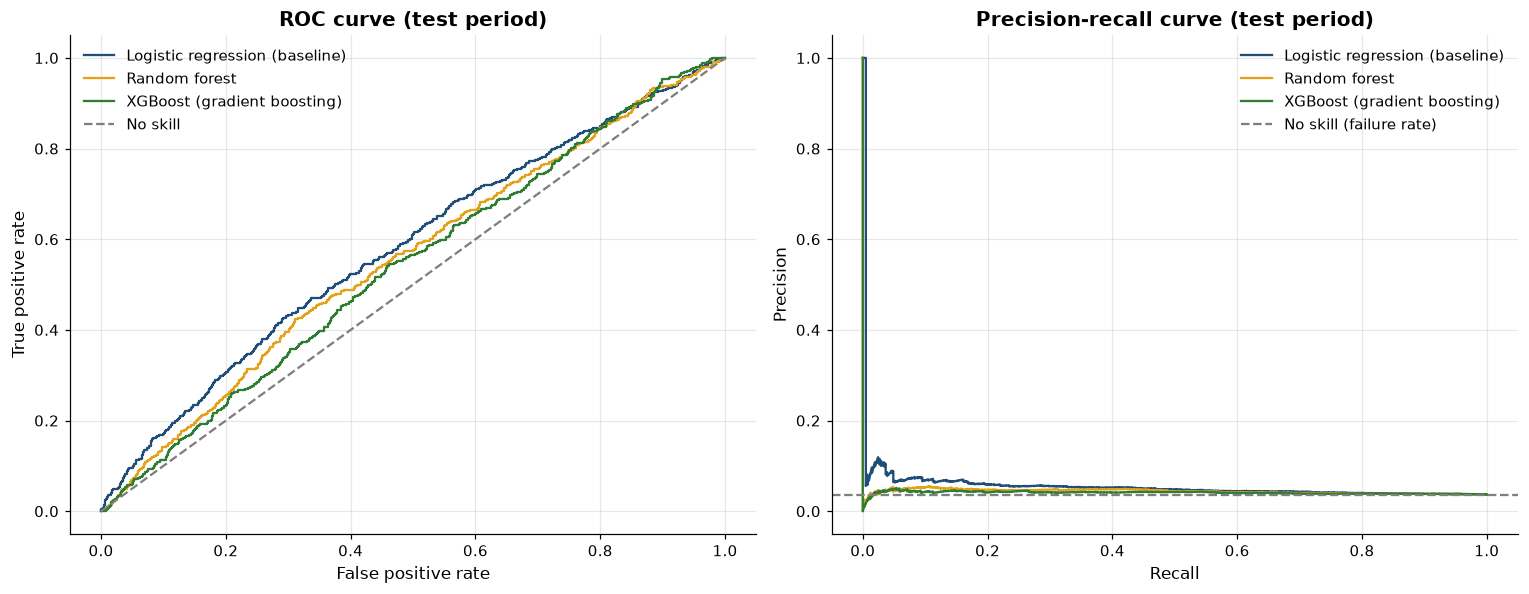

In [20]:
from sklearn.metrics import roc_curve, precision_recall_curve

y_test = suite["y_test"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colours = [PRIMARY, ACCENT, POSITIVE]
for colour, (name, proba) in zip(colours, suite["test_proba"].items()):
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=colour, label=name)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, color=colour, label=name)
axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle="--", label="No skill")
axes[0].set(title="ROC curve (test period)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color=NEUTRAL, linestyle="--", label="No skill (failure rate)")
axes[1].set(title="Precision-recall curve (test period)", xlabel="Recall", ylabel="Precision")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
save_figure(fig, "07_roc_pr_curves")
plt.show()

## 4. Confusion matrix at the adopted threshold

The matrix shows the actual outcome against the alert decision. With a low failure rate, a
high recall target forces the alert to cover most of the batches, so the false-alarm count is
large. That trade-off is the central business decision for QA.

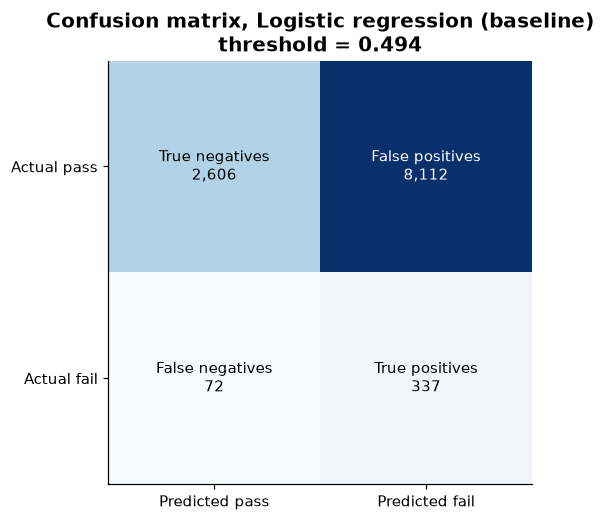

Flagged share: 75.9% of test batches


In [21]:
from sklearn.metrics import confusion_matrix

chosen = suite["chosen_model"]
proba = suite["test_proba"][chosen]
thr = suite["thresholds"][chosen]
pred = (proba >= thr).astype(int)
cm = confusion_matrix(y_test, pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
labels = [["True negatives", "False positives"], ["False negatives", "True positives"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted pass", "Predicted fail"])
ax.set_yticks([0, 1], ["Actual pass", "Actual fail"])
ax.set_title(f"Confusion matrix, {chosen}\nthreshold = {thr:.3f}")
ax.grid(False)
save_figure(fig, "08_confusion_matrix")
plt.show()
print(f"Flagged share: {pred.mean():.1%} of test batches")

## 5. Gains: how concentrated is the risk?

If QA reviewed only the highest-risk batches, how many failures would they reach? The gains
table ranks test batches by predicted probability and cuts them into deciles.

,batches,failures,failure_rate,cumulative_failures_share,lift
decile,,,,,
1,1113,69,0.0620,0.1687,1.6866
2,1113,54,0.0485,0.3007,1.3199
3,1112,51,0.0459,0.4254,1.2477
4,1113,36,0.0323,0.5134,0.8800
5,1113,36,0.0323,0.6015,0.8800
6,1112,41,0.0369,0.7017,1.0031
7,1113,30,0.0270,0.7751,0.7333
8,1112,29,0.0261,0.8460,0.7095
9,1113,33,0.0296,0.9267,0.8066


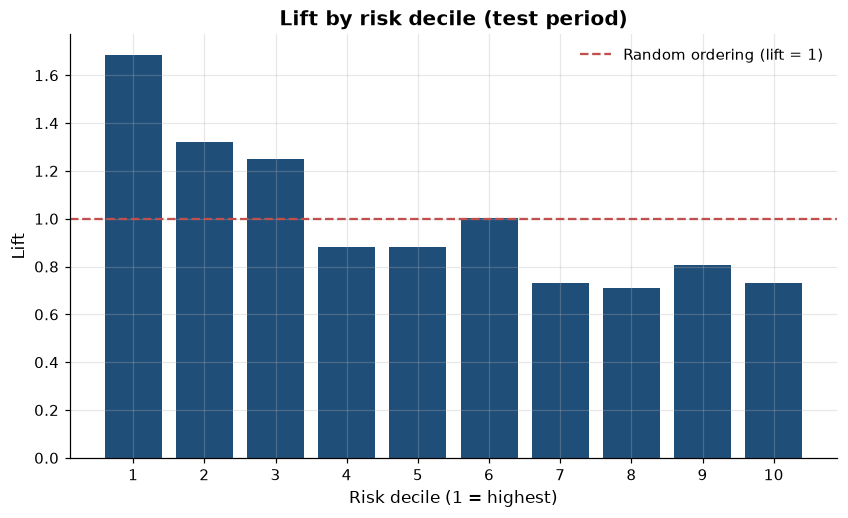

In [22]:
gains = pd.DataFrame({"y": y_test, "p": proba})
gains["decile"] = pd.qcut(gains["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
table = gains.groupby("decile", observed=True).agg(batches=("y", "size"), failures=("y", "sum"),
                                                    failure_rate=("y", "mean"))
table["cumulative_failures_share"] = table["failures"].cumsum() / table["failures"].sum()
table["lift"] = table["failure_rate"] / y_test.mean()
display(table.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(table.index.astype(str), table["lift"], color=PRIMARY)
ax.axhline(1, color=ALERT, linestyle="--", label="Random ordering (lift = 1)")
ax.set(title="Lift by risk decile (test period)", xlabel="Risk decile (1 = highest)", ylabel="Lift")
ax.legend()
save_figure(fig, "09_lift_by_decile")
plt.show()

## 6. What the model uses: permutation importance

Permutation importance measures how much the test-period ROC-AUC falls when one feature is
shuffled. It is a model-agnostic check on which inputs carry the signal. The bars show the
mean drop over five shuffles, and the thin lines show one standard deviation.

,feature,importance_mean,importance_std
label,,,
Operator experience (years),operator_experience_years,0.03840,0.00529
Raw material quality,raw_material_quality,0.01103,0.00603
Equipment age (years),equipment_age_years,0.00839,0.00423
Temperature variance,temp_variance,0.00746,0.00174
Batch size,batch_size,0.00678,0.00306
Dosage: Bolus,dosage_Bolus,0.00465,0.00179
Maintenance: Critical,maintenance_critical,0.00369,0.00091
Dosage: Syrup,dosage_Syrup,0.00284,0.00091
Maintenance: Due Soon,maintenance_due_soon,0.00273,0.00128


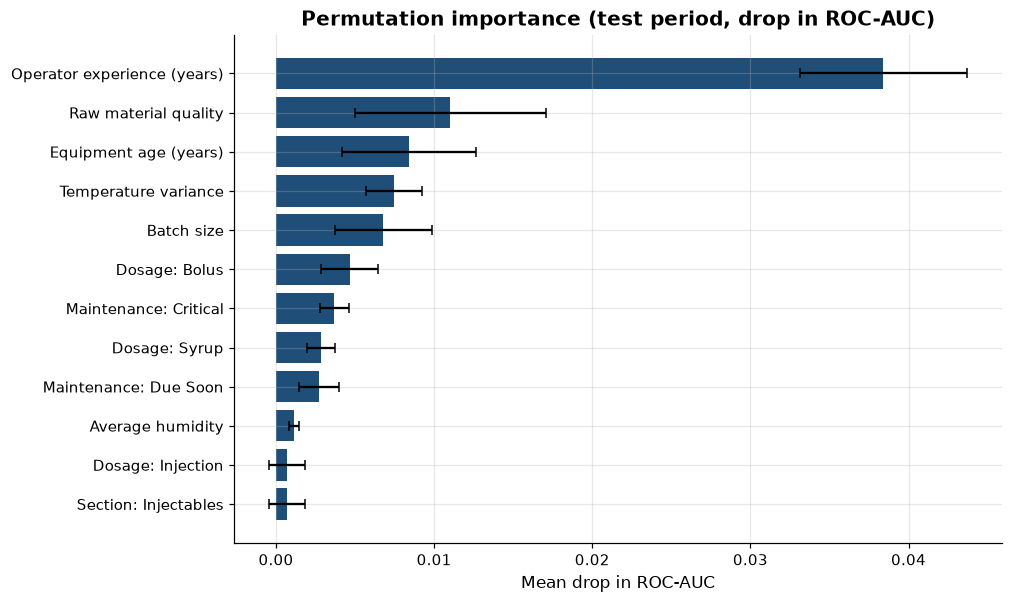

In [23]:
imp = suite["importance"].head(12).iloc[::-1]
display(suite["importance"].head(12).round(5).set_index("label"))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp["label"], imp["importance_mean"], xerr=imp["importance_std"], color=PRIMARY, capsize=3)
ax.set(title="Permutation importance (test period, drop in ROC-AUC)", xlabel="Mean drop in ROC-AUC")
save_figure(fig, "10_feature_importance")
plt.show()

## 7. Explaining individual alerts

For each batch, the model reports the three features that push its risk up the most, and a
recommended action tied to the leading driver. The chart uses the adopted model's own
contributions, so the explanation matches the prediction exactly.

In [24]:
from src.modeling import driver_contributions, top_drivers, recommended_action

contribs = driver_contributions(suite["models"][chosen], suite["X_test"])
drivers = top_drivers(contribs, n=3)
top_risk = pd.Series(proba, index=suite["X_test"].index).nlargest(5).index

example = batches.loc[top_risk, ["batch_id", "production_start", "drug_name", "equipment_id",
                                 "maintenance_status", "batch_passed"]].copy()
example["probability"] = proba[suite["X_test"].index.get_indexer(top_risk)]
example = example.join(drivers[["driver_1", "driver_2", "driver_3"]])
example["recommended_action"] = [recommended_action(f) for f in drivers.loc[top_risk, "driver_1_feature"]]
display(example.round(4).set_index("batch_id"))

,production_start,drug_name,equipment_id,maintenance_status,batch_passed,probability,driver_1,driver_2,driver_3,recommended_action
batch_id,,,,,,,,,,
SUS-24-0008,2024-02-19,Sucra Suspension,LAL/LIQ/003,Critical,0,0.8973,Maintenance: Critical,Equipment age (years),Temperature variance,Complete overdue maintenance on this equipment and confirm calibration befor...
AB3-24-0035,2024-10-08,Altoa 300mg Bolus,LAL/TAB/006,Current,0,0.8902,Temperature variance,Equipment age (years),Dosage: Bolus,Review the process trend for this run and verify environmental controls befo...
ACP-26-0009,2026-01-20,Acepril,LAL/TAB/006,Current,1,0.8770,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...
HMG-24-0063,2024-04-23,Homagon,LAL/TAB/010,Current,1,0.8760,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...
ALT-24-0106,2024-10-14,Altoa Tablets,LAL/TAB/006,Current,1,0.8628,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...


## 8. Failure-mode model

For each alert, the proposal asks for the likely failure mode. A random forest is trained on
failed batches only. The result is compared with the simplest possible guess (always predict
the most common mode), because a model that does not beat that guess adds no value.

In [25]:
from src.modeling import train_failure_type_model
from sklearn.metrics import accuracy_score, f1_score

train_fail = split.train[split.train[TARGET_COL] == 1]
test_fail = split.test[split.test[TARGET_COL] == 1]
X_tf_train = suite["X_train"].loc[train_fail.index]
X_tf_test = suite["X_test"].loc[test_fail.index]
ft_model = train_failure_type_model(X_tf_train, train_fail["failure_mode"])
pred_mode = ft_model.predict(X_tf_test)
actual_mode = test_fail["failure_mode"].to_numpy()
majority = train_fail["failure_mode"].value_counts().idxmax()

result = pd.DataFrame(
    {
        "accuracy": [accuracy_score(actual_mode, [majority] * len(actual_mode)), accuracy_score(actual_mode, pred_mode)],
        "macro_F1": [f1_score(actual_mode, [majority] * len(actual_mode), average="macro", zero_division=0),
                     f1_score(actual_mode, pred_mode, average="macro", zero_division=0)],
    },
    index=["Majority-class baseline", "Random forest"],
)
display(result.round(4))
print(f"Majority class in training: {majority}")
print("Interpretation: the failure-mode model does not beat the majority baseline on accuracy. "
      "Its macro F1 is higher, so it finds some rarer modes, but the signal is weak.")

,accuracy,macro_F1
Majority-class baseline,0.2861,0.0494
Random forest,0.1467,0.1232


Majority class in training: Assay
Interpretation: the failure-mode model does not beat the majority baseline on accuracy. Its macro F1 is higher, so it finds some rarer modes, but the signal is weak.


## 9. Targets against results

The table compares the proposal's Section 8 targets with what was achieved on the test period.
Targets that are not met are stated plainly rather than adjusted to fit the result.

In [26]:
t = suite["test_table"].loc[chosen]
targets = pd.DataFrame(
    [
        ("Recall at least 0.80 with precision at least 0.19",
         f"Recall {t['recall']:.2f}, precision {t['precision']:.3f} (flags {t['flag_rate']:.0%} of batches)",
         "Not met"),
        ("ROC-AUC at least 0.80", f"{t['roc_auc']:.3f}", "Not met"),
        ("Beats the logistic baseline by a meaningful margin",
         "The adopted model is the logistic baseline; no challenger cleared the margin.", "Not met"),
    ],
    columns=["Proposal target", "Achieved (test period)", "Status"],
)
display(targets.set_index("Proposal target"))
print("Conclusion: pre-release process records do not separate failing from passing batches well enough "
      "for an automated screen. Notebook 06 shows what the composite risk score can and cannot do.")

,Achieved (test period),Status
Proposal target,,
Recall at least 0.80 with precision at least 0.19,"Recall 0.82, precision 0.040 (flags 76% of batches)",Not met
ROC-AUC at least 0.80,0.581,Not met
Beats the logistic baseline by a meaningful margin,The adopted model is the logistic baseline; no challenger cleared the margin.,Not met


Conclusion: pre-release process records do not separate failing from passing batches well enough for an automated screen. Notebook 06 shows what the composite risk score can and cannot do.


# 04 Equipment reliability and maintenance effect (Module B)

**Purpose.** Quantify how equipment and maintenance status relate to batch failure, test
whether the Critical maintenance signal survives adjustment, rank equipment by failure
risk, and report reliability proxies.

**Important limit.** The data contains no repair times or downtime, so true MTBF and MTTR
cannot be measured. Batch failure is used as a proxy for equipment failure, and every
proxy is labelled as such. Repair times appear only as clearly labelled scenarios.

In [27]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [28]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Failure rate by maintenance status

,batches,failures,failure_rate,ci_low,ci_high,share_of_batches
maintenance_status,,,,,,
Current,54240,1687,0.0311,0.0297,0.0326,0.9040
Due Soon,5284,155,0.0293,0.0251,0.0342,0.0881
Critical,476,33,0.0693,0.0498,0.0958,0.0079


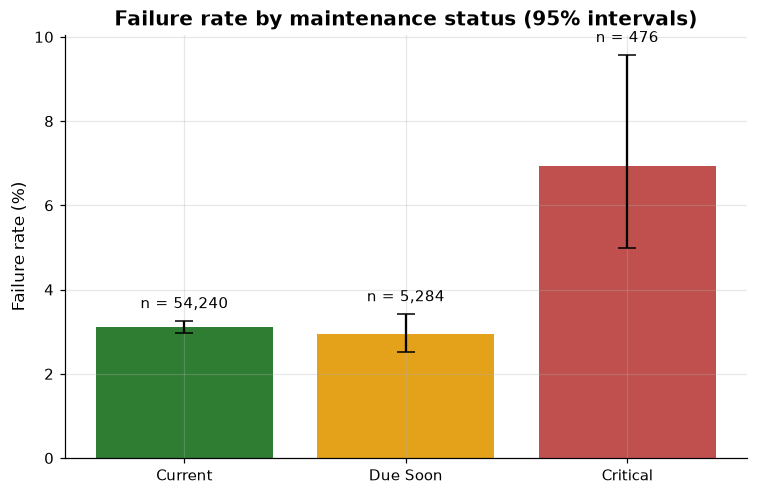

In [29]:
from src.reliability import status_summary

status = status_summary(batches)
display(status.round(4).set_index("maintenance_status"))

fig, ax = plt.subplots(figsize=(8, 5))
err = np.vstack([status["failure_rate"] - status["ci_low"], status["ci_high"] - status["failure_rate"]])
ax.bar(status["maintenance_status"], status["failure_rate"] * 100, yerr=err * 100, capsize=6,
       color=[POSITIVE, ACCENT, ALERT])
for i, row in status.iterrows():
    ax.text(i, row["ci_high"] * 100 + 0.3, f"n = {row['batches']:,}", ha="center")
ax.set(title="Failure rate by maintenance status (95% intervals)", ylabel="Failure rate (%)")
save_figure(fig, "11_status_rates")
plt.show()

## 2. Does the maintenance signal survive adjustment?

Unadjusted, Critical batches fail more often. The logistic model below adds equipment age,
operator experience, dosage form and section. The reference level is Current. A second
model adds equipment fixed effects, which compares batches within each machine and so
guards against maintenance status merely marking the least reliable machines.

In [30]:
from src.reliability import fit_maintenance_model, odds_ratio_table

adjusted = fit_maintenance_model(batches)
or_main = odds_ratio_table(adjusted)
display(or_main.round(4).set_index("term"))

fixed = fit_maintenance_model(batches, with_equipment_fixed_effects=True)
or_fixed = odds_ratio_table(fixed)
or_fixed = or_fixed[or_fixed["term"].str.contains("Maintenance|age|operator")]
print("Sensitivity: equipment fixed effects (within-machine comparison)")
display(or_fixed.round(4).set_index("term"))

,coefficient,odds_ratio,or_ci_low,or_ci_high,p_value
term,,,,,
Maintenance: Critical,0.8462,2.3308,1.6269,3.3392,0.0000
Maintenance: Due Soon,-0.0573,0.9443,0.7988,1.1163,0.5018
Equipment age (per year),0.0321,1.0326,1.0247,1.0406,0.0000
Operator experience (per year),-0.0356,0.9650,0.9579,0.9723,0.0000


Sensitivity: equipment fixed effects (within-machine comparison)


,coefficient,odds_ratio,or_ci_low,or_ci_high,p_value
term,,,,,
Maintenance: Critical,0.8548,2.3509,1.6397,3.3705,0.0000
Maintenance: Due Soon,-0.0497,0.9515,0.8049,1.1249,0.5606
Equipment age (per year),0.0345,1.0351,1.0261,1.0443,0.0000


### Forest plot of the adjusted odds ratios

An odds ratio above 1 means higher failure odds than the reference. A bar that does not
cross 1 is a statistically clear effect at the 95 percent level.

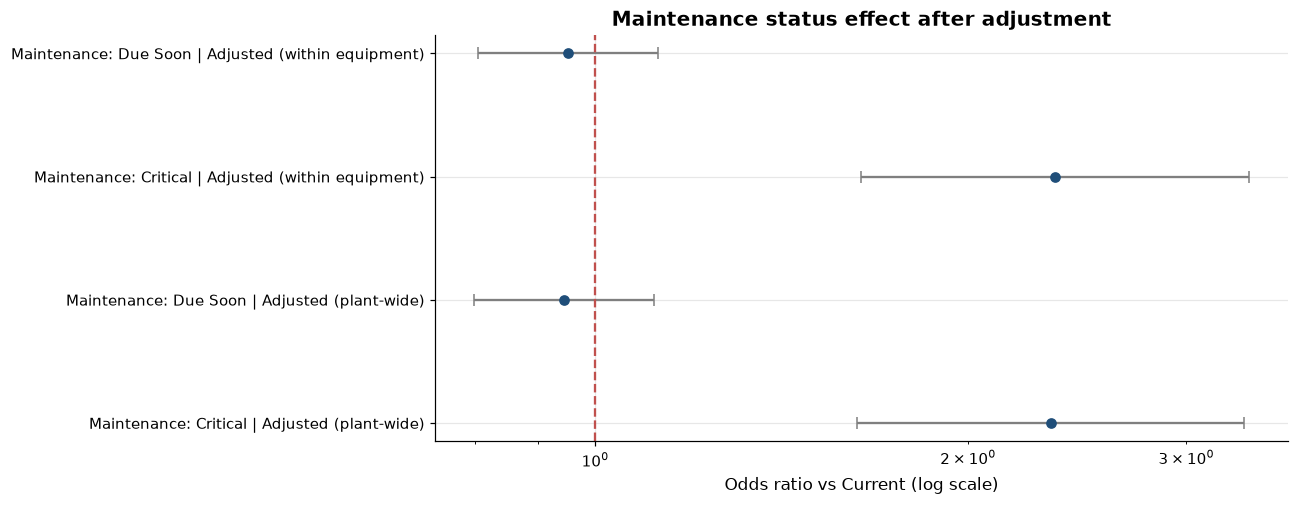

In [31]:
forest = pd.concat([
    or_main.assign(model="Adjusted (plant-wide)"),
    or_fixed.assign(model="Adjusted (within equipment)"),
])
forest = forest[forest["term"].str.contains("Maintenance")]
fig, ax = plt.subplots(figsize=(10, 4.8))
y_positions = np.arange(len(forest))
ax.errorbar(forest["odds_ratio"], y_positions,
            xerr=[forest["odds_ratio"] - forest["or_ci_low"], forest["or_ci_high"] - forest["odds_ratio"]],
            fmt="o", color=PRIMARY, ecolor=NEUTRAL, capsize=4)
ax.axvline(1, color=ALERT, linestyle="--")
ax.set_yticks(y_positions, [f"{t} | {m}" for t, m in zip(forest["term"], forest["model"])])
ax.set_xscale("log")
ax.set_xlabel("Odds ratio vs Current (log scale)")
ax.set_title("Maintenance status effect after adjustment")
save_figure(fig, "12_adjusted_odds_ratio")
plt.show()

## 3. Equipment ranking: observed versus expected failures

Machines differ in what they make, so raw failure rates are not a fair ranking. Indirect
standardisation computes the failures each machine would expect given its section and dosage
form, using plant-wide rates. The standardised ratio is observed over expected: a value above
1 means more failures than its product mix predicts. The exact Poisson interval shows whether
that excess is statistically clear.

,equipment_name,manufacturing_section,batches,failures,failure_rate,expected_failures,standardised_ratio,ratio_ci_low,ratio_ci_high,priority
equipment_id,,,,,,,,,,
LAL/TAB/023,Semi-Auto Capsule Filling Machine,Oral Solids,27,1,0.037,0.850,1.176,0.030,6.553,"Watch: above expected, interval includes 1"
LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,4097,158,0.039,145.126,1.089,0.926,1.272,"Watch: above expected, interval includes 1"
LAL/TAB/006,35 STN Compression Machine,Oral Solids,13411,472,0.035,435.133,1.085,0.989,1.187,"Watch: above expected, interval includes 1"
LAL/TAB/007,Coating Machine 1,Oral Solids,4784,152,0.032,141.297,1.076,0.912,1.261,"Watch: above expected, interval includes 1"
LAL/TAB/011,Capsule Filling Machine 2,Oral Solids,2932,93,0.032,92.329,1.007,0.813,1.234,"Watch: above expected, interval includes 1"
LAL/INJ/003,Ampoule Filling & Sealing Machine,Injectables,1068,51,0.048,51.000,1.000,0.745,1.315,Standard
LAL/CRM/001,Creams Mixing Tank,Creams & Ointments,1480,43,0.029,43.000,1.000,0.724,1.347,Standard
LAL/TAB/010,Capsule Filling Machine 1,Oral Solids,5107,160,0.031,160.820,0.995,0.847,1.162,Standard
LAL/TAB/028,61 STN B Tablet Compression Machine,Oral Solids,6222,177,0.028,181.732,0.974,0.836,1.128,Standard


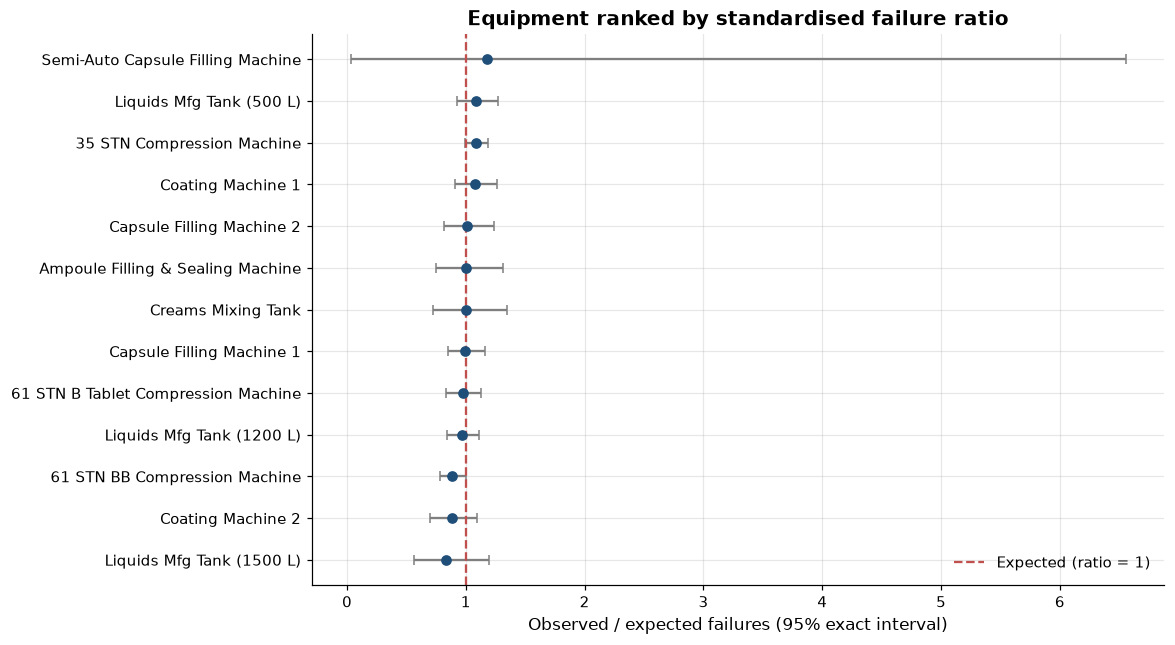

In [32]:
from src.reliability import equipment_table

equipment = equipment_table(batches)
view = equipment[["equipment_id", "equipment_name", "manufacturing_section", "batches", "failures",
                  "failure_rate", "expected_failures", "standardised_ratio", "ratio_ci_low",
                  "ratio_ci_high", "priority"]]
display(view.round(3).set_index("equipment_id"))

ordered = equipment.sort_values("standardised_ratio")
fig, ax = plt.subplots(figsize=(10, 6.5))
y_positions = np.arange(len(ordered))
ax.errorbar(ordered["standardised_ratio"], y_positions,
            xerr=[ordered["standardised_ratio"] - ordered["ratio_ci_low"],
                  ordered["ratio_ci_high"] - ordered["standardised_ratio"]],
            fmt="o", color=PRIMARY, ecolor=NEUTRAL, capsize=3)
ax.axvline(1, color=ALERT, linestyle="--", label="Expected (ratio = 1)")
ax.set_yticks(y_positions, ordered["equipment_name"])
ax.set_xlabel("Observed / expected failures (95% exact interval)")
ax.set_title("Equipment ranked by standardised failure ratio")
ax.legend()
save_figure(fig, "13_equipment_ratio")
plt.show()

## 4. Reliability proxies and labelled availability scenarios

The mean time between failures (MTBF) proxy is production hours per batch failure. Availability
needs a repair time, which the data does not contain. The three columns below use repair times of
2, 8 and 24 hours. These are assumptions for comparison only, not measurements.

In [33]:
proxy = equipment[["equipment_id", "equipment_name", "production_hours", "failures",
                   "proxy_mtbf_production_hours", "proxy_batches_between_failures",
                   "scenario_availability_mttr_2h", "scenario_availability_mttr_8h",
                   "scenario_availability_mttr_24h"]]
display(proxy.round(3).set_index("equipment_id"))
print("PROXY LABEL: MTBF here is production hours per batch failure. It is not a measured MTBF.")
print("SCENARIO LABEL: availability columns assume repair times of 2, 8 and 24 hours (assumptions).")

,equipment_name,production_hours,failures,proxy_mtbf_production_hours,proxy_batches_between_failures,scenario_availability_mttr_2h,scenario_availability_mttr_8h,scenario_availability_mttr_24h
equipment_id,,,,,,,,
LAL/TAB/023,Semi-Auto Capsule Filling Machine,218.8,1,218.800,27.000,0.991,0.965,0.901
LAL/LIQ/003,Liquids Mfg Tank (500 L),29476.3,158,186.559,25.930,0.989,0.959,0.886
LAL/TAB/006,35 STN Compression Machine,237588.7,472,503.366,28.413,0.996,0.984,0.954
LAL/TAB/007,Coating Machine 1,118919.0,152,782.362,31.474,0.997,0.990,0.970
LAL/TAB/011,Capsule Filling Machine 2,51048.6,93,548.910,31.527,0.996,0.986,0.958
LAL/INJ/003,Ampoule Filling & Sealing Machine,15269.1,51,299.394,20.941,0.993,0.974,0.926
LAL/CRM/001,Creams Mixing Tank,16534.3,43,384.519,34.419,0.995,0.980,0.941
LAL/TAB/010,Capsule Filling Machine 1,90504.3,160,565.652,31.919,0.996,0.986,0.959
LAL/TAB/028,61 STN B Tablet Compression Machine,192394.3,177,1086.973,35.153,0.998,0.993,0.978


PROXY LABEL: MTBF here is production hours per batch failure. It is not a measured MTBF.
SCENARIO LABEL: availability columns assume repair times of 2, 8 and 24 hours (assumptions).


## 5. Ranked maintenance list

The list ranks equipment by the standardised ratio and attaches a recommended maintenance step
to each priority level. The priority rule is conservative: a machine is treated as a clear
priority only when its excess failures are statistically clear.

In [34]:
action = {
    "High: above expected, interval excludes 1": "Schedule a condition review and root-cause check now.",
    "Watch: above expected, interval includes 1": "Review maintenance records and trend the process readings monthly.",
    "Standard": "Continue planned maintenance.",
}
ranked = equipment[["equipment_id", "equipment_name", "manufacturing_section", "batches", "failures",
                    "standardised_ratio", "priority"]].copy()
ranked.insert(0, "rank", range(1, len(ranked) + 1))
ranked["recommended_maintenance_step"] = ranked["priority"].map(action)
display(ranked.round(3).set_index("rank"))

,equipment_id,equipment_name,manufacturing_section,batches,failures,standardised_ratio,priority,recommended_maintenance_step
rank,,,,,,,,
1,LAL/TAB/023,Semi-Auto Capsule Filling Machine,Oral Solids,27,1,1.176,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
2,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,4097,158,1.089,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
3,LAL/TAB/006,35 STN Compression Machine,Oral Solids,13411,472,1.085,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
4,LAL/TAB/007,Coating Machine 1,Oral Solids,4784,152,1.076,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
5,LAL/TAB/011,Capsule Filling Machine 2,Oral Solids,2932,93,1.007,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
6,LAL/INJ/003,Ampoule Filling & Sealing Machine,Injectables,1068,51,1.000,Standard,Continue planned maintenance.
7,LAL/CRM/001,Creams Mixing Tank,Creams & Ointments,1480,43,1.000,Standard,Continue planned maintenance.
8,LAL/TAB/010,Capsule Filling Machine 1,Oral Solids,5107,160,0.995,Standard,Continue planned maintenance.
9,LAL/TAB/028,61 STN B Tablet Compression Machine,Oral Solids,6222,177,0.974,Standard,Continue planned maintenance.


# 05 Process control and the rise since 2019 (Module C)

**Purpose.** Check whether process conditions stay in control, whether out-of-control readings
come before failures, whether assay results are capable of meeting specification, and how much of
the rise in failures since 2019 is explained by the measured factors.

**Control limits** are set from passed batches up to 2021, so recent drift cannot distort them.
A reading is out of control when it lies outside mean plus or minus three standard deviations for
its manufacturing section. Variance measures use an upper limit only.

In [35]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [36]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Control limits from in-control history

In [37]:
from src.process_control import control_limits, flag_out_of_control, within_limits_share

limits = control_limits(batches)
display(limits.round(3).set_index(["manufacturing_section", "variable"]).head(10))
flags = flag_out_of_control(batches, limits)

baseline_n    mean     sd     lcl     ucl
manufacturing_section variable                                                    
Creams & Ointments    temp_avg                 1064  21.984  0.850  19.434  24.535
                      pressure_avg             1061   0.900  0.043   0.771   1.029
                      humidity_avg             1061  50.891  5.099  35.593  66.190
                      temp_variance            1054   0.383  0.405   0.000   1.598
                      pressure_variance        1053   0.045  0.039   0.000   0.163
Injectables           temp_avg                  694  20.839  0.603  19.029  22.648
                      pressure_avg              696   1.199  0.060   1.019   1.379
                      humidity_avg              694  48.989  3.953  37.130  60.847
                      temp_variance             697   0.229  0.186   0.000   0.786
                      pressure_variance         697   0.044  0.038   0.000   0.158

## 2. Control chart: temperature on the largest machine

The chart shows every batch on one machine over time. Limits come from the section's in-control
history. Red points are failed batches. Points outside the limits are the out-of-control signals
that the lead-time analysis tests.

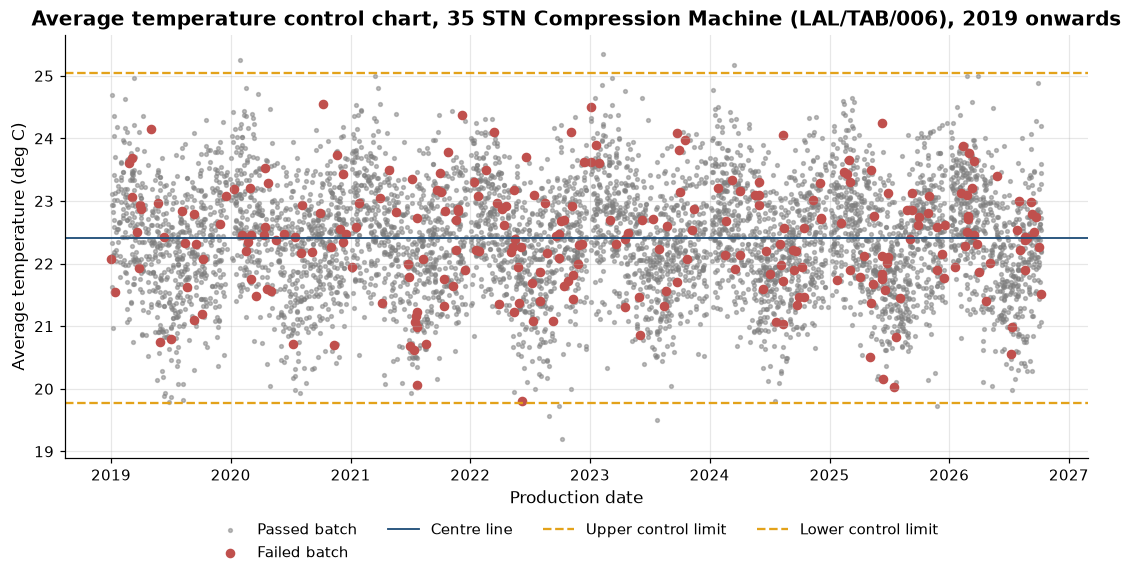

Batches shown: 5,895; failed: 262; out-of-control temperature readings: 8


In [38]:
machine = batches["equipment_id"].value_counts().idxmax()
name = batches.loc[batches["equipment_id"] == machine, "equipment_name"].iloc[0]
section = batches.loc[batches["equipment_id"] == machine, "manufacturing_section"].iloc[0]
sub = batches[batches["equipment_id"] == machine].copy()
sub = sub[sub["production_start"] >= "2019-01-01"]
lim = limits[(limits["manufacturing_section"] == section) & (limits["variable"] == "temp_avg")].iloc[0]

fig, ax = plt.subplots(figsize=(12, 5))
passed = sub[sub[TARGET_COL] == 0]
failed_b = sub[sub[TARGET_COL] == 1]
ax.scatter(passed["production_start"], passed["temp_avg"], s=6, color=NEUTRAL, alpha=0.5, label="Passed batch")
ax.scatter(failed_b["production_start"], failed_b["temp_avg"], s=28, color=ALERT, label="Failed batch")
ax.axhline(lim["mean"], color=PRIMARY, linewidth=1.2, label="Centre line")
ax.axhline(lim["ucl"], color=ACCENT, linestyle="--", label="Upper control limit")
ax.axhline(lim["lcl"], color=ACCENT, linestyle="--", label="Lower control limit")
ax.set(title=f"Average temperature control chart, {name} ({machine}), 2019 onwards",
       xlabel="Production date", ylabel="Average temperature (deg C)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save_figure(fig, "14_control_chart_temperature")
plt.show()
print(f"Batches shown: {len(sub):,}; failed: {len(failed_b)}; out-of-control temperature readings: "
      f"{int(flags.loc[sub.index, 'ooc_temp_avg'].sum())}")

## 3. Share of readings within control limits

The proposal's target is at least 90 percent of readings within limits, and every variable meets it.
The variance measures sit lower (about 98 percent) because their distributions are skewed to the right,
so a symmetric three-sigma limit flags more of their high readings. This is noted as a limitation.

,share_within_limits,readings_out_of_control
variable,,
temp_avg,0.9978,133
pressure_avg,0.9972,170
humidity_avg,0.9974,159
temp_variance,0.9784,1293
pressure_variance,0.9800,1202


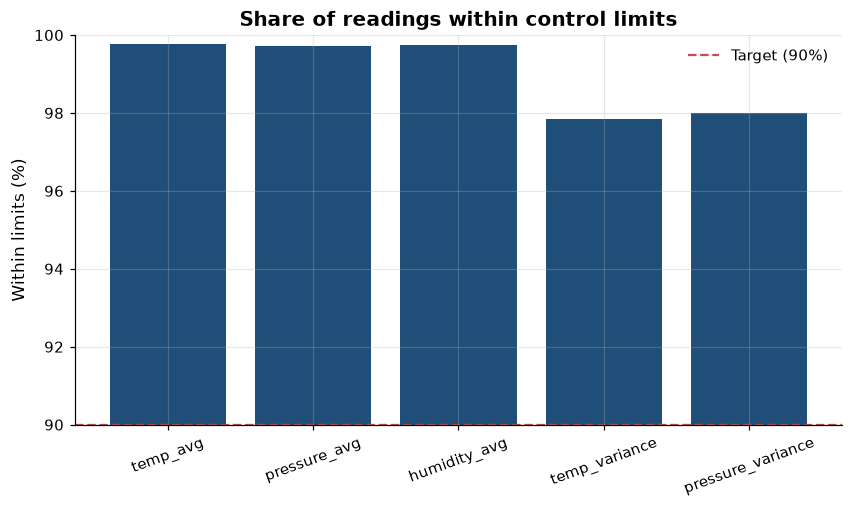

In [39]:
within = within_limits_share(flags)
display(within.round(4).set_index("variable"))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(within["variable"], within["share_within_limits"] * 100, color=PRIMARY)
ax.axhline(90, color=ALERT, linestyle="--", label="Target (90%)")
ax.set_ylim(90, 100)
ax.set(title="Share of readings within control limits", ylabel="Within limits (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend()
save_figure(fig, "15_within_limits")
plt.show()

## 4. Lead-time analysis: do failures follow warning signals?

For each batch, the test asks whether any of the five previous batches on the same machine had an
out-of-control reading. If warning signals come before failures, failed batches should show more
prior signals than passed batches.

In [40]:
from src.process_control import lead_time_analysis

lead = lead_time_analysis(batches, flags)
display(lead.round(4).set_index("outcome"))
rr = lead["relative_risk_of_prior_signal"].iloc[0]
pval = lead["chi_square_p_value"].iloc[0]
print(f"Relative risk of a prior signal before a failure: {rr:.2f} (chi-square p = {pval:.3f})")
print("Interpretation: the difference is small and not significant at the 5% level. Out-of-control "
      "readings do not give a usable early warning for these failures.")

,batches,share_with_prior_signal,relative_risk_of_prior_signal,chi_square_p_value
outcome,,,,
Passed,58125,0.2192,1.0805,0.074
Failed,1875,0.2368,1.0805,0.074


Relative risk of a prior signal before a failure: 1.08 (chi-square p = 0.074)
Interpretation: the difference is small and not significant at the 5% level. Out-of-control readings do not give a usable early warning for these failures.


## 5. Capability of the assay against specification

Process capability compares the spread of a result with its specification limits. Cpk of 1.33 or
more is conventionally considered capable. The assay limits of 95 to 105 percent are an assumption,
because the data carries no specification fields.

,n,mean,sd,cp,cpk,share_out_of_spec,capable_at_1_33
manufacturing_section,,,,,,,
Creams & Ointments,1480,100.0656,2.5233,0.6605,0.6518,0.0405,False
Injectables,1068,100.0409,1.8558,0.8981,0.8907,0.0131,False
Oral Liquids,12170,99.9860,2.4122,0.6909,0.6890,0.0270,False
Oral Solids,45282,99.9904,1.3291,1.2540,1.2516,0.0089,False


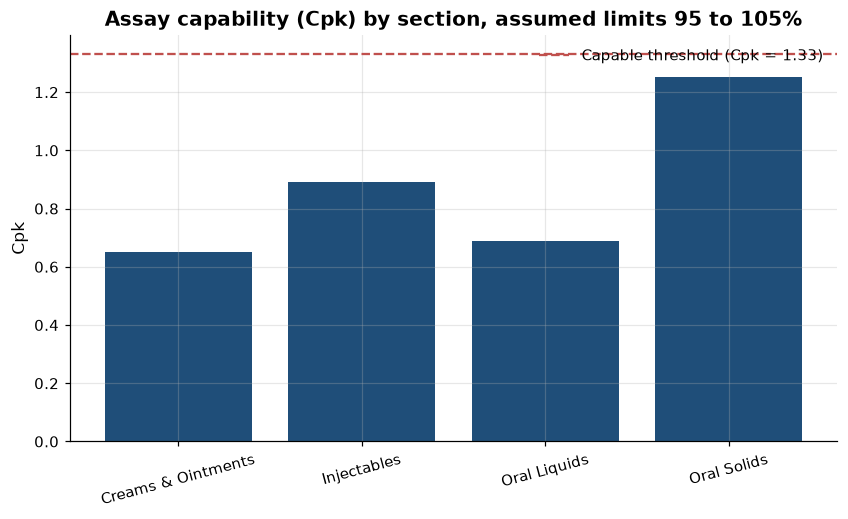

In [41]:
from src.process_control import capability

cap = capability(batches)
display(cap.round(4).set_index("manufacturing_section"))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(cap["manufacturing_section"], cap["cpk"], color=PRIMARY)
ax.axhline(1.33, color=ALERT, linestyle="--", label="Capable threshold (Cpk = 1.33)")
ax.set(title="Assay capability (Cpk) by section, assumed limits 95 to 105%", ylabel="Cpk")
ax.tick_params(axis="x", rotation=15)
ax.legend()
save_figure(fig, "16_capability")
plt.show()

## 6. The rise since 2019: how much do the measured factors explain?

The period comparison uses 2014 to 2018 against 2020 to 2025, following the proposal. 2019 is shown
separately as the turning point. The decomposition asks how much of the change in failure rate the
measured factors can account for. It does this in two ways: by the change in predicted risk given
each period's actual mix, and by the year-trend coefficient before and after adjustment.

In [42]:
from src.trend import run_trend_analysis

trend = run_trend_analysis(batches)
display(trend.periods.round(4).set_index("measure"))
display(trend.decomposition.round(4).set_index("quantity"))
display(trend.year_coefficients.round(4).set_index("model"))

period,Pre (2014-2018),Post (2020-2025)
measure,,
batches,15250.0000,22233.0000
failures,424.0000,829.0000
failure_rate,0.0278,0.0373
mean_equipment_age_years,8.0955,14.4713
share_critical,0.0050,0.0115
share_operators_0_2_years,0.1855,0.1274
share_injectables,0.0241,0.0184
share_liquid_batches,0.2292,0.2031
mean_operator_experience_years,8.5414,9.4052


,value
quantity,
"Actual failure rate, pre (2014-2018)",0.0278
"Actual failure rate, post (2020-2025)",0.0373
Actual change (percentage points),0.9484
Change predicted by measured factors (percentage points),0.5709
Share of change explained by measured factors,0.6020
Unexplained change (percentage points),0.3775


,year_coefficient,odds_ratio_per_year,p_value,share_of_trend_absorbed
model,,,,
Year trend only,0.0297,1.0302,0.000,NaN
"Year trend, adjusted for measured factors",0.0023,1.0023,0.723,0.9218


### Composition: what changed between the two periods

Equipment age, operator experience and maintenance status are the measured factors that moved most.
The chart shows the share of batches in each age band in the two periods.

period,Post (2020-2025),Pre (2014-2018)
band,,
0-2 yrs,0.00,9.61
2-5 yrs,0.58,21.13
5-10 yrs,22.79,33.85
10+ yrs,76.63,35.41


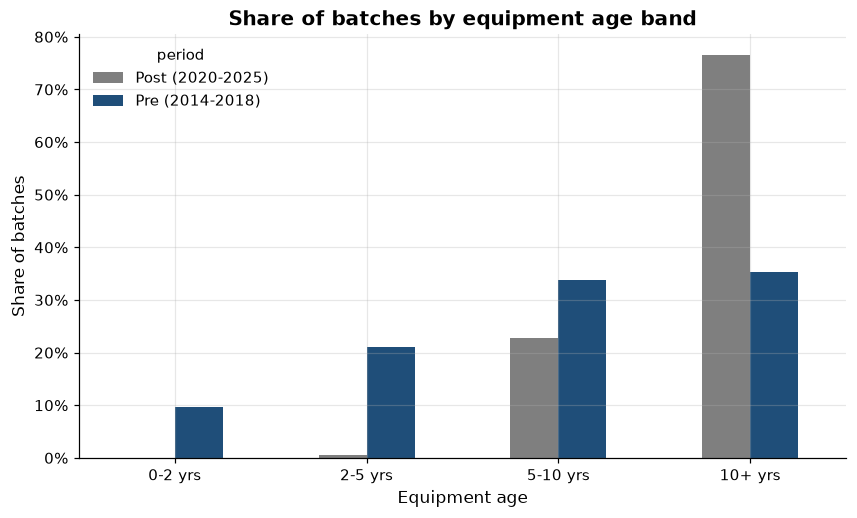

In [43]:
comp = trend.composition[trend.composition["band_type"] == "Equipment age"]
pivot = comp.pivot(index="band", columns="period", values="share").reindex(
    ["0-2 yrs", "2-5 yrs", "5-10 yrs", "10+ yrs"])
display((pivot * 100).round(2))

fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot.bar(ax=ax, color=[NEUTRAL, PRIMARY])
ax.set(title="Share of batches by equipment age band", xlabel="Equipment age", ylabel="Share of batches")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, "17_age_composition")
plt.show()

# 06 Risk view and the business back-test (Module D)

**Purpose.** Combine quality, equipment and process risk into one score for every batch, attach a
driver and a recommended action to each alert, and replay the alert rules on the 2024 to 2026 test
period. Benefits are reported as simulated, not realised.

**Score.** Each component is a percentile rank from 0 to 1. The weights are 0.6 for quality, 0.2 for
equipment and 0.2 for process. These weights are an assumption pending stakeholder sign-off.

In [44]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [45]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Build the risk score on the test period

The score needs the adopted classifier's probability, the number of out-of-control readings per batch,
and each batch's leading driver. The pipeline produces all of these, so the notebook reads the
alert table it wrote.

In [46]:
from src.config import RISK_WEIGHTS, HIGH_RISK_TIER_SHARE

alerts = load_processed("alerts_test_period").set_index("index")
print(f"Test-period batches scored: {len(alerts):,}")
print("Weights:", RISK_WEIGHTS, "| High tier = top", f"{HIGH_RISK_TIER_SHARE:.0%}", "of batches")
display(alerts[["quality_component", "equipment_component", "process_component",
                "risk_score", "risk_tier", "classifier_flag"]].describe().round(3))

Test-period batches scored: 11,127
Weights: {'quality': 0.6, 'equipment': 0.2, 'process': 0.2} | High tier = top 10% of batches


,quality_component,equipment_component,process_component,risk_score,classifier_flag
count,11127.000,11127.000,11127.000,11127.000,11127.000
mean,0.500,0.274,0.012,0.357,0.759
std,0.289,0.163,0.049,0.192,0.428
min,0.000,0.000,0.000,0.003,0.000
25%,0.250,0.135,0.000,0.195,1.000
50%,0.500,0.275,0.000,0.354,1.000
75%,0.750,0.401,0.000,0.520,1.000
max,1.000,0.869,0.400,0.814,1.000


## 2. Score distribution and tiers

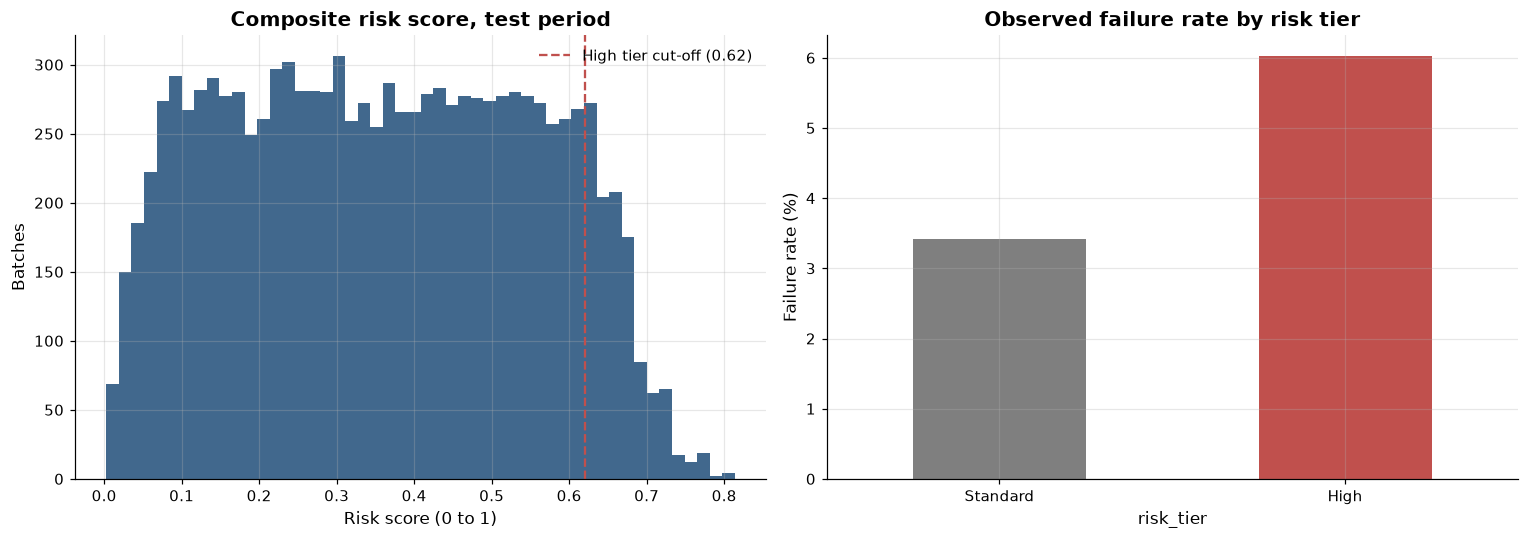

,failure_rate
risk_tier,
Standard,0.0342
High,0.0602


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(alerts["risk_score"], bins=50, color=PRIMARY, alpha=0.85)
cut = alerts.loc[alerts["risk_tier"] == "High", "risk_score"].min()
axes[0].axvline(cut, color=ALERT, linestyle="--", label=f"High tier cut-off ({cut:.2f})")
axes[0].set(title="Composite risk score, test period", xlabel="Risk score (0 to 1)", ylabel="Batches")
axes[0].legend()
tier_rates = alerts.groupby("risk_tier")["batch_passed"].apply(lambda s: 1 - s.mean()).reindex(["Standard", "High"])
tier_rates.mul(100).plot.bar(ax=axes[1], color=[NEUTRAL, ALERT])
axes[1].set(title="Observed failure rate by risk tier", ylabel="Failure rate (%)")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
save_figure(fig, "18_risk_distribution")
plt.show()
display(tier_rates.rename("failure_rate").to_frame().round(4))

## 3. The back-test: what would each rule have caught?

The two rules are compared on the same 2024 to 2026 batches. The first is the classifier alert at its
validation-set threshold. The second is the High tier of the composite score. The comparison reports the
share of failures caught, the share of batches flagged, the lift, and the batch volume that would have
been held. Volumes are kept in kilograms and litres separately, because the data has no monetary value.

rule,Classifier alert at 80% recall target,High risk tier (top 10% by composite score)
batches_flagged,8.449000e+03,1113.0000
share_of_batches_flagged,7.593000e-01,0.1000
failures_in_period,4.090000e+02,409.0000
failures_caught,3.370000e+02,67.0000
share_of_failures_caught,8.240000e-01,0.1638
failure_rate_flagged,3.990000e-02,0.0602
failure_rate_not_flagged,2.690000e-02,0.0342
lift_flagged_vs_base,1.085100e+00,1.6377
volume_flagged_kg,1.002480e+06,65640.0000
volume_flagged_litres,1.285460e+06,175120.0000


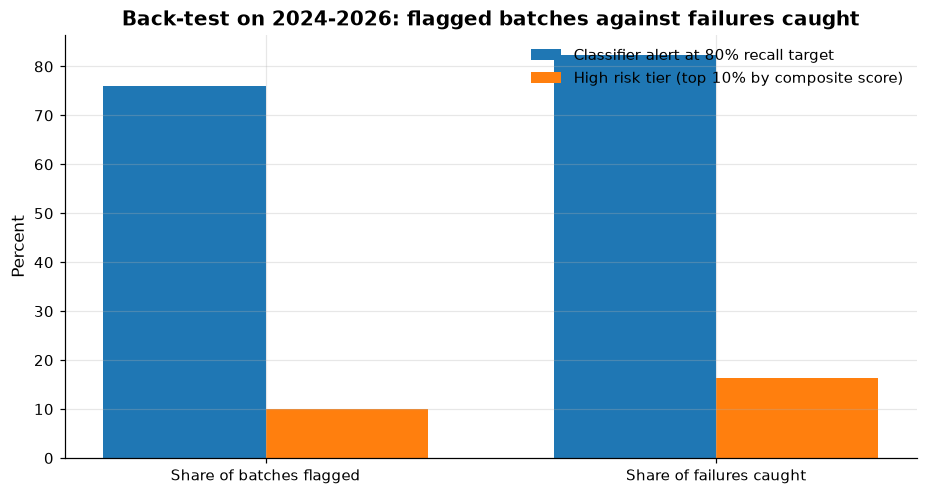

In [48]:
summary = pd.read_csv(ROOT / "reports" / "tables" / "backtest_summary.csv").set_index("rule")
display(summary.round(4).T)

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.36
labels = ["Share of batches flagged", "Share of failures caught"]
for i, (rule, row) in enumerate(summary.iterrows()):
    values = [row["share_of_batches_flagged"] * 100, row["share_of_failures_caught"] * 100]
    ax.bar(np.arange(2) + (i - 0.5) * width, values, width, label=rule)
ax.set_xticks(range(2), labels)
ax.set(title="Back-test on 2024-2026: flagged batches against failures caught", ylabel="Percent")
ax.legend()
save_figure(fig, "19_backtest_rules")
plt.show()

### Stability by year

A rule that works only in one year would be unsafe to rely on. The table repeats the back-test for each year.

In [49]:
by_year = pd.read_csv(ROOT / "reports" / "tables" / "backtest_by_year.csv").set_index("year")
display(by_year[["batches_flagged", "failures_in_period", "failures_caught",
                 "share_of_failures_caught", "failure_rate_flagged", "failure_rate_not_flagged"]].round(4))

,batches_flagged,failures_in_period,failures_caught,share_of_failures_caught,failure_rate_flagged,failure_rate_not_flagged
year,,,,,,
2024,2904,142,122,0.8592,0.0420,0.0208
2025,3056,156,126,0.8077,0.0412,0.0303
2026,2489,111,89,0.8018,0.0358,0.0302


### Critical equipment: does the flag line up with the maintenance signal?

In [50]:
crit = pd.read_csv(ROOT / "reports" / "tables" / "backtest_critical_equipment.csv").set_index("group")
display(crit.round(4))
print("Small numbers: the Critical group in the test period has few batches, so the rate is indicative only.")

,batches,failures,failure_rate
group,,,
Critical maintenance status,79,8,0.1013
Current or Due Soon,11048,401,0.0363


Small numbers: the Critical group in the test period has few batches, so the rate is indicative only.


## 4. Alert list for the High tier

Each alert shows the batch, its leading driver, and the recommended action. Operator identifiers are
pseudonymised. The full alert list is exported for the dashboard and for QA.

In [51]:
high = alerts[alerts["risk_tier"] == "High"].sort_values("risk_score", ascending=False)
cols = ["batch_id", "production_start", "drug_name", "equipment_id", "maintenance_status",
        "risk_score", "primary_driver", "recommended_action", "operator_pseudo_id"]
display(high[cols].head(15).round(3).set_index("batch_id"))

export_path = ROOT / "reports" / "tables" / "high_risk_alerts_test_period.csv"
high[cols + ["batch_passed", "failure_mode"]].to_csv(export_path, index=False)
print(f"High-tier alerts exported: {len(high):,} rows -> {export_path.relative_to(ROOT)}")

,production_start,drug_name,equipment_id,maintenance_status,risk_score,primary_driver,recommended_action,operator_pseudo_id
batch_id,,,,,,,,
SUS-24-0008,2024-02-19,Sucra Suspension,LAL/LIQ/003,Critical,0.814,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-F30B3280
SUS-24-0009,2024-02-27,Sucra Suspension,LAL/LIQ/003,Critical,0.813,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-C8C8C160
LRS-24-0015,2024-02-28,Lorata Syrup,LAL/LIQ/003,Critical,0.813,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-C8C8C160
ALS-24-0027,2024-03-11,Altoa Suspension,LAL/LIQ/003,Critical,0.813,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-CDEDFA6A
AB3-26-0023,2026-07-21,Altoa 300mg Bolus,LAL/TAB/006,Due Soon,0.785,Equipment age (years),Complete overdue maintenance on this equipment and confirm calibration befor...,OP-1E5B30BB
ZRS-26-0031,2026-04-16,Zerocin Suspension,LAL/LIQ/003,Due Soon,0.782,Temperature variance,Review the process trend for this run and verify environmental controls befo...,OP-AD58AB2B
SUS-25-0025,2025-10-23,Sucra Suspension,LAL/LIQ/003,Due Soon,0.778,Equipment age (years),Complete overdue maintenance on this equipment and confirm calibration befor...,OP-F30B3280
HMG-25-0167,2025-10-09,Homagon,LAL/TAB/011,Critical,0.775,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-4857C862
KMX-25-0138,2025-09-16,Kemoxyl,LAL/TAB/011,Critical,0.774,Temperature variance,Review the process trend for this run and verify environmental controls befo...,OP-F9F34231


High-tier alerts exported: 1,113 rows -> reports\tables\high_risk_alerts_test_period.csv


## 5. What this notebook established

* The composite score's High tier concentrates failures more than the classifier alert does, at a much
  smaller batch volume. The tier is selected mainly by the classifier probability, so its lift is only as
  good as the classifier's ranking. The leading driver shown to QA is most often equipment age, which is
  a stable and explainable signal.
* The classifier's alert at the 80 percent recall target flags most batches and gives little lift, so it
  is not recommended as an automatic hold rule.
* Simulated savings are not reported, because the data has no monetary value. Volumes are reported instead.

# 07 Demand forecasting (optional module E)

**Purpose.** Forecast monthly unit demand from the sales history, and compare three methods against the
seasonal-naive baseline on the most recent 12 months. The proposal's target is a WAPE at least 15 percent
better than the baseline.

**Scope.** Monthly forecasts only. Weekly demand is listed as an extension in the tracker. Cancelled
orders are excluded, because they are not real demand.

In [52]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: C:\Users\Eng Joe\Desktop\sales\batch_quality_project (1)\batch_quality_project


In [53]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Monthly demand series

Units sold per month are aggregated by product category. The total is the sum of all categories.

Product_Category,Clinical_Supplies,Consumables,Equipment,Glassware,PPE,Reagents,Total
year_month,,,,,,,
2025-07-01,3762,4979,272,3575,3786,3884,20258
2025-08-01,3325,3364,262,3126,3643,4370,18090
2025-09-01,4418,4625,294,4323,3582,3973,21215
2025-10-01,3839,4635,343,5161,5173,4517,23668
2025-11-01,4605,5146,318,4007,4017,4200,22293
2025-12-01,5117,4035,359,4468,5577,4526,24082


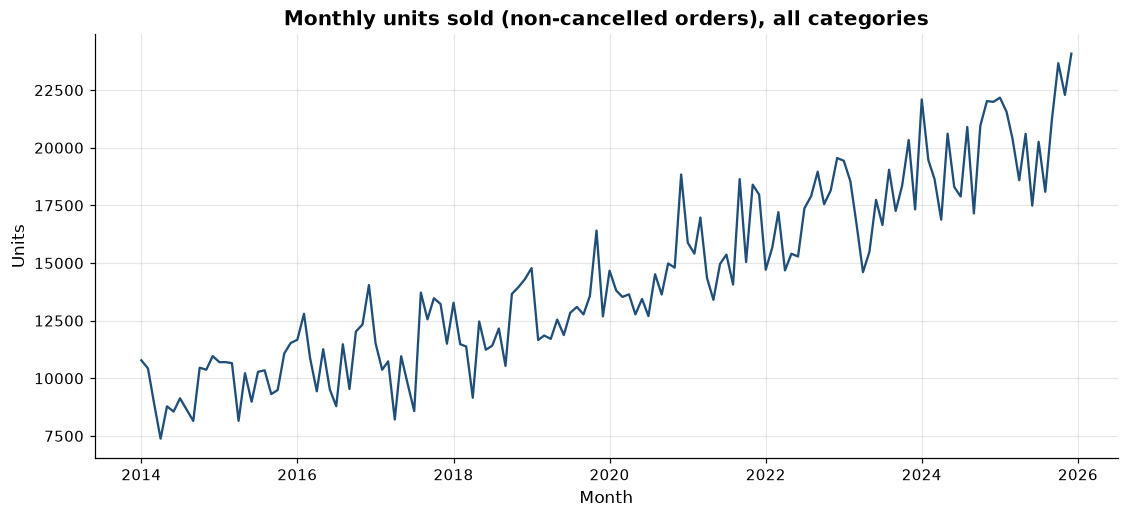

In [54]:
from src.forecasting import monthly_demand

demand = monthly_demand(sales)
display(demand.tail(6).round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(demand.index, demand["Total"], color=PRIMARY)
ax.set(title="Monthly units sold (non-cancelled orders), all categories", xlabel="Month", ylabel="Units")
save_figure(fig, "20_monthly_demand")
plt.show()

## 2. Seasonality

A year-by-month heatmap shows whether demand has a repeating pattern. Strong seasonality favours
seasonal methods over flat ones.

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2014,10.8,10.4,8.9,7.4,8.8,8.6,9.1,8.6,8.2,10.5,10.4,11.0
2015,10.7,10.7,10.7,8.2,10.2,9.0,10.3,10.3,9.3,9.5,11.1,11.5
2016,11.7,12.8,10.9,9.4,11.3,9.5,8.8,11.5,9.5,12.0,12.3,14.0
2017,11.5,10.4,10.7,8.2,11.0,9.7,8.6,13.7,12.6,13.5,13.2,11.5
2018,13.3,11.5,11.4,9.2,12.5,11.2,11.4,12.2,10.5,13.7,14.0,14.3
2019,14.8,11.7,11.9,11.7,12.5,11.9,12.8,13.1,12.8,13.6,16.4,12.7
2020,14.7,13.8,13.5,13.6,12.8,13.4,12.7,14.5,13.6,15.0,14.8,18.8
2021,15.9,15.4,17.0,14.4,13.4,15.0,15.4,14.1,18.6,15.0,18.4,18.0
2022,14.7,15.7,17.2,14.7,15.4,15.3,17.4,17.9,19.0,17.6,18.2,19.6


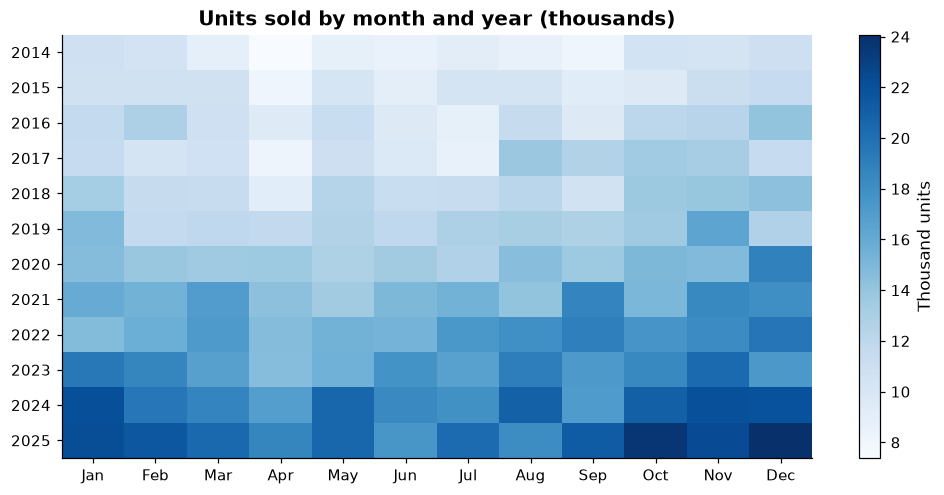

In [55]:
heat = demand["Total"].to_frame("units")
heat["year"] = heat.index.year
heat["month"] = heat.index.month
pivot = heat.pivot(index="year", columns="month", values="units")
display((pivot / 1000).round(1))

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pivot.values / 1000, cmap="Blues", aspect="auto")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_title("Units sold by month and year (thousands)")
fig.colorbar(im, ax=ax, label="Thousand units")
ax.grid(False)
save_figure(fig, "21_seasonality_heatmap")
plt.show()

## 3. Forecast accuracy on the 12-month holdout

The series is split at the last 12 months. Each method is fitted on the earlier history and forecasts the
holdout. WAPE is the main metric: total absolute error divided by total actual demand.

In [56]:
from src.forecasting import evaluate_series

accuracy_table, forecast_table = evaluate_series(demand["Total"])
display(accuracy_table.round(4))

base = accuracy_table.loc["Seasonal naive (baseline)", "WAPE"]
best = accuracy_table["WAPE"].idxmin()
gain = accuracy_table.loc[best, "WAPE_improvement_vs_baseline"]
status = "Met" if gain >= 0.15 else "Not met"
print(f"Best method: {best}. WAPE improvement over seasonal naive: {gain:.1%}. Target 15%: {status}.")

,WAPE,RMSE,Bias,WAPE_improvement_vs_baseline
method,,,,
Seasonal naive (baseline),0.0830,2099.2308,-0.0540,0.0000
Moving average (3 months),0.0825,2139.7429,0.0378,0.0053
"Holt-Winters (damped, seasonal)",0.0518,1410.3885,-0.0102,0.3751


Best method: Holt-Winters (damped, seasonal). WAPE improvement over seasonal naive: 37.5%. Target 15%: Met.


## 4. Forecast against actual demand

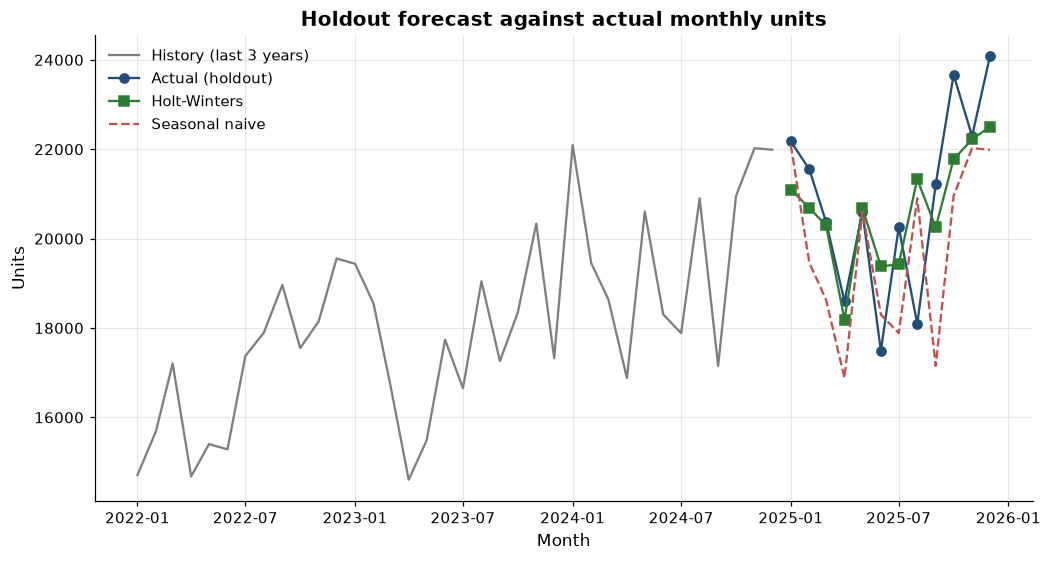

In [57]:
fig, ax = plt.subplots(figsize=(11, 5.5))
hist = demand["Total"].iloc[:-len(forecast_table)]
ax.plot(hist.index[-36:], hist.iloc[-36:], color=NEUTRAL, label="History (last 3 years)")
ft = forecast_table.set_index("month")
ax.plot(ft.index, ft["actual"], color=PRIMARY, marker="o", label="Actual (holdout)")
ax.plot(ft.index, ft["Holt-Winters (damped, seasonal)"], color=POSITIVE, marker="s", label="Holt-Winters")
ax.plot(ft.index, ft["Seasonal naive (baseline)"], color=ALERT, linestyle="--", label="Seasonal naive")
ax.set(title="Holdout forecast against actual monthly units", xlabel="Month", ylabel="Units")
ax.legend()
save_figure(fig, "22_forecast_holdout")
plt.show()

## 5. Reading the result

Seasonal-naive repeats last year's pattern exactly, which is hard to beat when the pattern is stable.
Holt-Winters learns both trend and seasonality, and damps the trend so the forecast does not run away.
A method that is best on total demand may still be weak on individual categories. Category-level accuracy
is a natural next step before any reorder decisions are made.